# End-to-End ML Pipeline V3: Breast Cancer Diagnosis (Healthcare) with pandas, SQL, scikit-learn + TensorFlow/Keras

**V3 = V2 + the interview concept checklist.** One runnable notebook that covers the full workflow *and* every concept you may be asked to walk through. Anything that can't live naturally in the pipeline is drilled in **Section 18 (practice problems)**, with solutions hidden in Appendix B.

| Section | Concept checklist item |
|---|---|
| 0. Requirements & methodology | End-to-end process |
| 1. Setup: imports, each one commented | Main libraries & what they do |
| 2. Load the CSV into a DataFrame (pandas + NumPy) | Packages used to load data |
| 3. First look: EDA commands → outputs | EDA commands |
| 4. Find nulls, then replace them | Null handling |
| 5. Quality checks & data manipulation: observation → action | Manipulating / updating data in Python |
| 6. EDA visuals: command → visual → finding | EDA visuals |
| 7. SQL inside the notebook: `ROW_NUMBER()` and friends | ROW_NUMBER, SQL |
| 8. Split the data (stratified 60/20/20) | Splitting |
| 9. Preprocess with no leakage | Splitting / leakage |
| 10. Models: baselines with leak-free cross-validation | Models you ran |
| 11. Keras network: overfitting vs Dropout | Models you ran |
| 12. Validate outputs: thresholds, selection, test once, CIs | Validation |
| 13. Calibration | Validation |
| 14. What drives the predictions | Observations |
| 15. Score a new batch with integrity checks | End-to-end process |
| 16. Stakeholder summary | Reporting |
| 17. End-to-end recap (one diagram) | End-to-end process |
| 18. Practice problems (self-checking) | Everything not fully exercised above |
| 19. Interview Q&A | All 10 checklist items |
| Appendix A. Same network in PyTorch | Models you ran |
| Appendix B. Practice solutions | — |

**Data:** [UCI Breast Cancer Wisconsin (Diagnostic)](https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic): 569 tumors, 30 numeric features computed from a digitized image of a fine-needle aspirate (FNA) of a breast mass (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension; each as mean, standard error, and "worst"). Label: **M = malignant, B = benign**. Public, de-identified research data; **no PHI**. Any IDs in the practice problems are synthetic.

**Runs in:** Google Colab or local Jupyter (Python 3.10+, pandas, NumPy, scikit-learn, seaborn, tensorflow; PyTorch only for Appendix A).

## 0. Requirements & methodology

- **Business question:** given FNA measurements, which tumors should be flagged as likely malignant for priority review?
- **Unit of analysis:** one row = one tumor sample. Target `diagnosis` (1 = malignant).
- **Cost of errors:** a missed malignancy (false negative) is far worse than an extra review (false positive) → **optimize recall on malignant**, keep precision acceptable.
- **Success criteria (set before modeling):** test recall ≥ 0.95 with ROC-AUC ≥ 0.97; beat or match a logistic-regression baseline, or explain why not. Report a 95% confidence interval, not just the point estimate.
- **Selection rule (set before modeling):** tune each candidate's threshold on validation to catch ≥ 97% of malignant tumors; among candidates that hit it, pick the highest precision; ties go to the simpler model.
- **Method:** load CSV → first-look EDA → find and fix nulls → quality checks and manipulation → visual EDA → SQL checks → stratified train/val/test split → preprocess (fit on train only) → baselines with leak-free CV → Keras network → select model + threshold on validation → evaluate once on the untouched test set with bootstrap CIs → check calibration → explain drivers → score new batches through schema checks → report.
- **Human in the loop:** the model prioritizes cases for a pathologist; it does not make the diagnosis.

## 1. Setup: imports, with what each library does

Interview line: *"pandas for tabular data, NumPy for the math underneath it, matplotlib/seaborn for EDA plots, sqlite3 so I can run SQL in the notebook, scikit-learn for splitting, preprocessing, classic models and metrics, and TensorFlow/Keras for the neural network."*

In [1]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")   # hide TensorFlow C++ startup noise

import logging                     # structured logs (timestamp, level, message) instead of bare print()
import sqlite3                     # built-in SQL engine: load a DataFrame into a table and run real SQL on it
from pathlib import Path           # file paths that work on Mac, Windows, and Colab

import numpy as np                 # arrays + math: np.where, np.nan, np.log1p, np.percentile, random generators
import pandas as pd                # DataFrames: read_csv, info, describe, isnull, fillna, groupby, merge, pivot_table
import matplotlib.pyplot as plt    # base plotting: figures, subplots, histograms, line plots
import seaborn as sns              # statistical plots on matplotlib: countplot, histplot, boxplot, heatmap, pairplot
import tensorflow as tf            # deep learning framework
from tensorflow import keras       # high-level TF API: Sequential models, layers, callbacks
from tensorflow.keras import layers  # Dense, Dropout, Input building blocks

from sklearn.datasets import load_breast_cancer                      # bundled offline copy of the same UCI data
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold  # splitting + CV
from sklearn.pipeline import Pipeline, make_pipeline                 # chain preprocessing + model, fit as one object
from sklearn.impute import SimpleImputer, KNNImputer                 # fill missing values (learned on train only)
from sklearn.preprocessing import StandardScaler                     # z-score scaling: mean 0, std 1
from sklearn.linear_model import LogisticRegression                  # linear baseline, interpretable
from sklearn.tree import DecisionTreeClassifier                      # single tree: interpretable, high variance
from sklearn.ensemble import RandomForestClassifier                  # bagged trees: lower variance
from sklearn.calibration import calibration_curve                    # reliability curve for probabilities
from sklearn.metrics import (confusion_matrix, classification_report, roc_auc_score, brier_score_loss,
                             precision_recall_curve, recall_score, precision_score, f1_score)  # evaluation

logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(name)s %(message)s", force=True)
logging.getLogger("matplotlib").setLevel(logging.WARNING)            # silence plotting chatter
log = logging.getLogger("bc_pipeline")

SEED = 42
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)
sns.set_theme(style="whitegrid")
print("pandas", pd.__version__, "| numpy", np.__version__, "| tensorflow", tf.__version__)

I0000 00:00:1795203272.213251   17594 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795203272.214074   17594 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1795203273.358403   17594 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795203273.358815   17594 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


pandas 3.0.5 | numpy 2.5.3 | tensorflow 2.21.0


## 2. Load the CSV into a DataFrame (pandas, plus the NumPy alternative)

**Which package loads a CSV?** `pandas.read_csv` → a DataFrame with column names and mixed types (text label + numbers). NumPy can read CSVs too (`np.genfromtxt`, `np.loadtxt`), but only into one homogeneous numeric array with no column names, so it's the wrong tool for a file with a text `diagnosis` column.

The cell below writes the file in the common Kaggle layout (`id, diagnosis, 30 features`, plus a trailing comma on every line), downloading from UCI when internet is available and falling back to scikit-learn's bundled copy otherwise. Then it loads it exactly the way you would load any CSV.

In [2]:
UCI_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/wdbc.data"
BASE = ["radius", "texture", "perimeter", "area", "smoothness", "compactness",
        "concavity", "concave_points", "symmetry", "fractal_dimension"]
FEATURES = [f"{b}_{s}" for s in ("mean", "se", "worst") for b in BASE]   # UCI column order
TARGET = "diagnosis"
CSV_PATH = Path("breast_cancer_data.csv")


def write_source_csv(path: Path) -> None:
    """Write the dataset as a Kaggle-style CSV (trailing comma -> an empty last column)."""
    try:
        src = pd.read_csv(UCI_URL, header=None, names=["id", TARGET, *FEATURES])
        log.info("downloaded %d rows from UCI", len(src))
    except (OSError, ValueError) as exc:            # no internet / blocked host
        log.warning("UCI download failed (%s); using scikit-learn's bundled copy", type(exc).__name__)
        bc = load_breast_cancer()
        src = pd.DataFrame(bc.data, columns=FEATURES)
        src.insert(0, TARGET, np.where(bc.target == 0, "M", "B"))   # sklearn encodes 0 = malignant
        src.insert(0, "id", np.arange(842302, 842302 + len(src)))  # synthetic sample IDs
    src[""] = np.nan                                 # reproduces the trailing comma in the Kaggle file
    src.to_csv(path, index=False)


if not CSV_PATH.exists():
    write_source_csv(CSV_PATH)

try:
    raw = pd.read_csv(CSV_PATH)                      # <- the main loader: CSV -> DataFrame
except FileNotFoundError:
    log.exception("CSV not found at %s (in Colab, upload it or rerun the cell above)", CSV_PATH)
    raise
log.info("loaded %s rows=%d cols=%d", CSV_PATH, *raw.shape)

# NumPy alternative: numeric columns only, no header, no names
X_np = np.genfromtxt(CSV_PATH, delimiter=",", skip_header=1, usecols=range(2, 32))
assert X_np.shape == (len(raw), 30)
print("numpy array:", X_np.shape, X_np.dtype, "| first row, first 3 values:", X_np[0, :3])

2026-11-20 14:34:34,126 WARNING bc_pipeline UCI download failed (URLError); using scikit-learn's bundled copy


2026-11-20 14:34:34,151 INFO bc_pipeline loaded breast_cancer_data.csv rows=569 cols=33


numpy array: (569, 30) float64 | first row, first 3 values: [ 17.99  10.38 122.8 ]


## 3. First look: EDA commands → what each one outputs

| Command | Output | What you look for |
|---|---|---|
| `df.shape` | `(rows, cols)` | expected size? |
| `df.head()` / `df.tail()` / `df.sample(5)` | rows | column names, units, obvious junk |
| `df.columns` | column names | odd names like `Unnamed: 32` |
| `df.info()` | dtype + non-null count per column | nulls, numbers stored as text |
| `df.dtypes.value_counts()` | count per dtype | everything numeric except the label? |
| `df.describe().T` | count/mean/std/min/quartiles/max | ranges, impossible values, scale differences |
| `df[col].value_counts(normalize=True)` | class shares | imbalance |
| `df.nunique()` | distinct values per column | constants, IDs |
| `df.duplicated().sum()` | count of duplicate rows | duplicates |
| `df.isnull().sum()` | nulls per column | missing data (Section 4) |
| `df.memory_usage(deep=True).sum()` | bytes | will it scale? |

In [3]:
print("shape:", raw.shape)
print("columns (last 4):", list(raw.columns[-4:]))
display(raw.head())
display(raw.sample(3, random_state=SEED))
raw.info()

shape: (569, 33)
columns (last 4): ['concave_points_worst', 'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32']


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842303,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,842304,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,842305,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,842306,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
204,842506,B,12.47,18.60,81.09,481.9,0.09965,0.1058,0.08005,0.03821,...,24.64,96.05,677.9,0.1426,0.2378,0.2671,0.1015,0.3014,0.08750,NaN
70,842372,M,18.94,21.31,123.60,1130.0,0.09009,0.1029,0.10800,0.07951,...,26.58,165.90,1866.0,0.1193,0.2336,0.2687,0.1789,0.2551,0.06589,NaN
131,842433,M,15.46,19.48,101.70,748.9,0.10920,0.1223,0.14660,0.08087,...,26.00,124.90,1156.0,0.1546,0.2394,0.3791,0.1514,0.2837,0.08019,NaN


<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave_points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             569 non-null

In [4]:
print(raw.dtypes.value_counts(), "\n")
display(raw.describe().T.head(12))
print(raw[TARGET].value_counts(), "\n")
print(raw[TARGET].value_counts(normalize=True).round(3), "\n")
print("fewest distinct values:\n", raw.nunique().sort_values().head(4), "\n")
print("duplicate rows:", raw.duplicated().sum(), "| duplicate ids:", raw["id"].duplicated().sum())
print(f"memory: {raw.memory_usage(deep=True).sum() / 1024:.0f} KB")

float64    31
int64       1
str         1
Name: count, dtype: int64 



,count,mean,std,min,25%,50%,75%,max
id,569.0,842586.000000,164.400426,842302.00000,842444.00000,842586.00000,842728.00000,842870.00000
radius_mean,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.78000,28.11000
texture_mean,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.80000,39.28000
perimeter_mean,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.10000,188.50000
area_mean,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.70000,2501.00000
smoothness_mean,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.10530,0.16340
compactness_mean,569.0,0.104341,0.052813,0.01938,0.06492,0.09263,0.13040,0.34540
concavity_mean,569.0,0.088799,0.079720,0.00000,0.02956,0.06154,0.13070,0.42680
concave_points_mean,569.0,0.048919,0.038803,0.00000,0.02031,0.03350,0.07400,0.20120
symmetry_mean,569.0,0.181162,0.027414,0.10600,0.16190,0.17920,0.19570,0.30400


diagnosis
B    357
M    212
Name: count, dtype: int64 

diagnosis
B    0.627
M    0.373
Name: proportion, dtype: float64 

fewest distinct values:
 Unnamed: 32           0
diagnosis             2
smoothness_worst    411
symmetry_mean       432
dtype: int64 

duplicate rows: 0 | duplicate ids: 0
memory: 170 KB


**What the first look shows:**
- 569 rows × 33 columns: `id`, `diagnosis`, 30 features, and **`Unnamed: 32`**, an all-empty column created by the trailing comma.
- `diagnosis` is text (`M`/`B`), so it needs encoding. Everything else is numeric.
- About **37% malignant**: imbalanced but not extreme. Accuracy alone would mislead (always guessing benign scores ~63%).
- Scales differ wildly: `area_worst` reaches ~4,250 while `smoothness_mean` is ~0.1, so distance- and gradient-based models need scaling.
- No duplicate rows or IDs.

## 4. Find nulls, then replace them

**Find:** `df.isnull().sum()` (count), `df.isnull().mean()*100` (percent), `df.info()` (non-null counts), `df[df.isnull().any(axis=1)]` (the rows themselves).

**Replace, depending on the case:**

| Situation | Fix | pandas / sklearn |
|---|---|---|
| Column is 100% null (file artifact) | drop the column | `df.drop(columns=...)` or `df.dropna(axis=1, how="all")` |
| A handful of rows, missing at random | drop the rows | `df.dropna(subset=[...])` |
| Numeric, skewed | median | `df[c].fillna(df[c].median())` |
| Numeric, roughly symmetric | mean | `SimpleImputer(strategy="mean")` |
| Categorical | most frequent | `df[c].fillna(df[c].mode()[0])` |
| Features strongly correlated | neighbors | `KNNImputer(n_neighbors=5)` |
| Missingness itself may be informative | add a flag | `SimpleImputer(add_indicator=True)` |
| **Modeling** | learn the fill on **train only**, reuse on val/test | `imputer.fit(X_train)` → `.transform(X_test)` |

In [5]:
null_counts = raw.isnull().sum().sort_values(ascending=False)
print("nulls per column (top 3):\n", null_counts.head(3), "\n")
null_pct = raw.isnull().mean().mul(100).round(1)
print("columns with any nulls (%):\n", null_pct[null_pct > 0])

# Finding: 'Unnamed: 32' is 100% null -> a file-format artifact, not data -> drop it.
clean = raw.dropna(axis=1, how="all").copy()
assert "Unnamed: 32" not in clean.columns
assert clean[FEATURES].isnull().sum().sum() == 0, "real features should have no nulls"
print("\nafter dropping all-null columns:", clean.shape, "| nulls left:", int(clean.isnull().sum().sum()))

nulls per column (top 3):
 Unnamed: 32    569
id               0
diagnosis        0
dtype: int64 

columns with any nulls (%):
 Unnamed: 32    100.0
dtype: float64

after dropping all-null columns: (569, 32) | nulls left: 0


The real features have no nulls, so to practice the fixes we **inject** missing values (5% of rows in three columns) into a copy, then compare strategies against the true values we hid. This shows *why* the choice matters, not just the syntax.

In [6]:
rng = np.random.default_rng(SEED)
demo = clean.copy()
DEMO_COLS = ["texture_mean", "smoothness_mean", "area_worst"]
masks = {}
for col in DEMO_COLS:
    masks[col] = rng.random(len(demo)) < 0.05
    demo.loc[masks[col], col] = np.nan
print("injected nulls:\n", demo[DEMO_COLS].isnull().sum(), "\n")
display(demo[demo[DEMO_COLS].isnull().any(axis=1)].head(3)[["id", TARGET, *DEMO_COLS]])

# 1) drop rows
dropped = demo.dropna(subset=DEMO_COLS)
print(f"dropna: kept {len(dropped)} of {len(demo)} rows ({1 - len(dropped)/len(demo):.0%} of data lost)")

# 2) median, 3) mean, 4) per-class median (EDA only: uses the label, so it leaks into a model), 5) KNN
filled = {
    "median": demo[DEMO_COLS].fillna(demo[DEMO_COLS].median()),
    "mean": demo[DEMO_COLS].fillna(demo[DEMO_COLS].mean()),
    "class median (EDA only)": demo.groupby(TARGET)[DEMO_COLS].transform(lambda s: s.fillna(s.median())),
    "KNN (5 neighbors)": pd.DataFrame(
        KNNImputer(n_neighbors=5).fit_transform(StandardScaler().fit_transform(demo[FEATURES])),
        columns=FEATURES, index=demo.index)[DEMO_COLS],
}
# KNN ran in scaled space; convert back to original units for a fair error comparison
sd, mu = clean[FEATURES].std(ddof=0), clean[FEATURES].mean()
filled["KNN (5 neighbors)"] = filled["KNN (5 neighbors)"] * sd[DEMO_COLS] + mu[DEMO_COLS]

err_rows = []
for name, f in filled.items():
    assert f.isnull().sum().sum() == 0, f"{name} left nulls"
    err = {c: np.sqrt(np.mean((f.loc[masks[c], c] - clean.loc[masks[c], c]) ** 2)) / clean[c].std()
           for c in DEMO_COLS}
    err_rows.append({"strategy": name, **{c: round(v, 2) for c, v in err.items()}})
print("\nerror on the hidden true values (RMSE in standard deviations; lower is better):")
display(pd.DataFrame(err_rows).set_index("strategy"))

injected nulls:
 texture_mean       25
smoothness_mean    32
area_worst         21
dtype: int64 



,id,diagnosis,texture_mean,smoothness_mean,area_worst
19,842321,B,14.36,0.09779,NaN
20,842322,B,15.71,NaN,630.5
22,842324,M,14.26,0.10730,NaN


dropna: kept 493 of 569 rows (13% of data lost)

error on the hidden true values (RMSE in standard deviations; lower is better):


,texture_mean,smoothness_mean,area_worst
strategy,,,
median,1.09,0.91,1.23
mean,1.09,0.91,1.19
class median (EDA only),1.01,0.80,0.83
KNN (5 neighbors),0.68,0.52,0.19


**How to read it:** median and mean land about one standard deviation off, because they ignore everything else about the tumor. **KNN** is far more accurate on `area_worst` because size features are 0.9+ correlated, so the neighbors' sizes predict the missing one. Note KNN here was fit on all rows for the demo; in a model, it must be fit on train only, just like the imputer below.

**The modeling rule:** split first, learn fill values from train, apply them everywhere.

In [7]:
X_demo, y_demo = demo[FEATURES], (demo[TARGET] == "M").astype(int)
Xtr_d, Xte_d, _, _ = train_test_split(X_demo, y_demo, test_size=0.2, stratify=y_demo, random_state=SEED)

imputer = SimpleImputer(strategy="median", add_indicator=True)  # indicator = "was this value missing?"
Xtr_filled = imputer.fit_transform(Xtr_d)     # fit: learn the medians from TRAIN rows only
Xte_filled = imputer.transform(Xte_d)         # transform: reuse the train medians on test

assert not np.isnan(Xtr_filled).any() and not np.isnan(Xte_filled).any()
learned = pd.Series(imputer.statistics_, index=FEATURES)[DEMO_COLS]
assert np.allclose(learned, Xtr_d[DEMO_COLS].median()), "medians must come from train only"
print("medians learned from train:\n", learned.round(4))
print("added indicator columns:", Xtr_filled.shape[1] - len(FEATURES))

medians learned from train:
 texture_mean        18.9850
smoothness_mean      0.0951
area_worst         683.9500
dtype: float64
added indicator columns: 3


## 5. Quality checks & data manipulation: observation → action

Each step below states what was observed and what was done about it.

In [8]:
# 5a. Encode the label: M -> 1 (malignant, the class we must catch), B -> 0
assert set(clean[TARGET].unique()) == {"M", "B"}, f"unexpected labels: {clean[TARGET].unique()}"
clean[TARGET] = clean[TARGET].map({"M": 1, "B": 0}).astype(int)

# 5b. IDs are keys, not features: keep them aside, never feed them to a model
ids = clean.pop("id")
assert ids.is_unique

# 5c. Impossible values: sizes can't be negative
size_cols = [f for f in FEATURES if f.split("_")[0] in ("radius", "perimeter", "area")]
assert (clean[size_cols] >= 0).all().all(), "negative size measurement"

# 5d. Zeros: concavity == 0 is possible (perfectly smooth cells) -> review, don't delete
zero_rows = clean[(clean.filter(like="concav") == 0).any(axis=1)]
print(f"rows with a zero concavity value: {len(zero_rows)}; "
      f"malignant among them: {zero_rows[TARGET].sum()}  -> real smooth benign cells, kept")

# 5e. Duplicates and dtypes
assert not clean.duplicated().any()
assert clean[FEATURES].apply(pd.api.types.is_numeric_dtype).all()
print("label distribution:", clean[TARGET].value_counts().to_dict(), "| columns:", clean.shape[1])

rows with a zero concavity value: 13; malignant among them: 0  -> real smooth benign cells, kept
label distribution: {0: 357, 1: 212} | columns: 31


In [9]:
# 5f. Manipulate / update for EDA in a separate frame, so the model only sees the 30 original features
eda = clean.copy()
eda.insert(0, "id", ids)
eda["label"] = np.where(eda[TARGET] == 1, "malignant", "benign")           # readable label for plots
eda["area_log"] = np.log1p(eda["area_mean"])                              # new column: tame right skew
eda["size_band"] = pd.qcut(eda["radius_mean"], q=3, labels=["small", "medium", "large"])  # binning
eda["growth_ratio"] = eda["area_worst"] / eda["area_mean"]                 # derived feature
eda["high_concavity"] = 0
eda.loc[eda["concave_points_worst"] > 0.2, "high_concavity"] = 1           # conditional update with .loc
eda = eda.rename(columns={"concave_points_mean": "concave_pts_mean"})       # rename a column...
eda = eda.rename(columns={"concave_pts_mean": "concave_points_mean"})       # ...and back

print("sorted + filtered: largest 3 malignant tumors")
display(eda.query("label == 'malignant'").sort_values("area_mean", ascending=False)
           .head(3)[["id", "area_mean", "radius_mean", "size_band"]])

print("groupby + agg: class profile")
display(eda.groupby("label")[["radius_mean", "area_mean", "concave_points_mean", "texture_mean"]]
           .agg(["median", "mean"]).round(3))

print("crosstab: % malignant by size band")
display(pd.crosstab(eda["size_band"], eda["label"], normalize="index").round(2))

print("pivot_table: % malignant by size band x high concavity")
display(eda.pivot_table(index="size_band", columns="high_concavity", values=TARGET,
                        aggfunc="mean", observed=True).round(2))

# transform: add each row's class median back onto the row (a groupby that keeps the row count)
eda["area_vs_class_median"] = eda["area_mean"] / eda.groupby("label")["area_mean"].transform("median")
assert len(eda) == len(clean)

sorted + filtered: largest 3 malignant tumors


,id,area_mean,radius_mean,size_band
461,842763,2501.0,27.42,large
212,842514,2499.0,28.11,large
180,842482,2250.0,27.22,large


groupby + agg: class profile


radius_mean         area_mean          concave_points_mean         \
               median    mean    median     mean              median   mean   
label                                                                         
benign         12.200  12.147     458.4  462.790               0.023  0.026   
malignant      17.325  17.463     932.0  978.376               0.086  0.088   

          texture_mean          
                median    mean  
label                           
benign           17.39  17.915  
malignant        21.46  21.605

crosstab: % malignant by size band


label,benign,malignant
size_band,,
small,0.97,0.03
medium,0.79,0.21
large,0.12,0.88


pivot_table: % malignant by size band x high concavity


high_concavity,0,1
size_band,,
small,0.02,1.0
medium,0.17,1.0
large,0.82,1.0


In [10]:
# 5g. Multicollinearity: which feature pairs are nearly duplicates?
corr = clean[FEATURES].corr()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print("feature pairs with |r| > 0.95:")
display(upper[upper.abs() > 0.95].sort_values(ascending=False).round(3).to_frame("r"))

feature pairs with |r| > 0.95:


,,r
radius_mean,perimeter_mean,0.998
radius_worst,perimeter_worst,0.994
radius_mean,area_mean,0.987
perimeter_mean,area_mean,0.987
radius_worst,area_worst,0.984
perimeter_worst,area_worst,0.978
radius_se,perimeter_se,0.973
perimeter_mean,perimeter_worst,0.970
radius_mean,radius_worst,0.970
perimeter_mean,radius_worst,0.969


**Observations → actions:**

| Observation | Action |
|---|---|
| `Unnamed: 32` 100% null | dropped (Section 4) |
| Label is text M/B | mapped to 1/0, malignant = 1 |
| `id` is unique and meaningless to the tumor | removed from features, kept aside for joins and scoring |
| No negative sizes, no duplicates, all numeric | asserted, so a bad future file fails loudly |
| 13 rows with zero concavity, all benign | kept: smooth benign cells are real |
| ~37% malignant | stratified split, class-weighted models, recall-focused metrics |
| Features on scales from ~0.001 to ~4,000 | `StandardScaler` fit on train only (Section 9) |
| radius / perimeter / area correlated at 0.99+ | don't read their coefficients individually; grouped importance (Section 14) |
| Large tumors are ~88% malignant, small ~3% | size is the dominant signal; confirmed by the model in Section 14 |

## 6. EDA visuals: command → visual → finding

| Command | Visual | Question it answers |
|---|---|---|
| `sns.countplot(x="label", data=eda)` | bar chart | how imbalanced are the classes? |
| `sns.histplot(data=eda, x=f, hue="label", kde=True)` | overlaid histograms | how does each feature's distribution differ by class? skew? |
| `pd.melt(...)` + `sns.boxplot(...)` | box plots of standardized features | which features separate the classes; outliers |
| `sns.scatterplot(x=..., y=..., hue="label")` | scatter | can two features split the classes? |
| `sns.heatmap(df.corr())` | correlation heatmap | multicollinearity |
| `sns.pairplot(..., hue="label")` | grid of scatters + histograms | pairwise relationships at once |
| `df.hist(figsize=...)` | one histogram per column | quick skew/outlier scan |

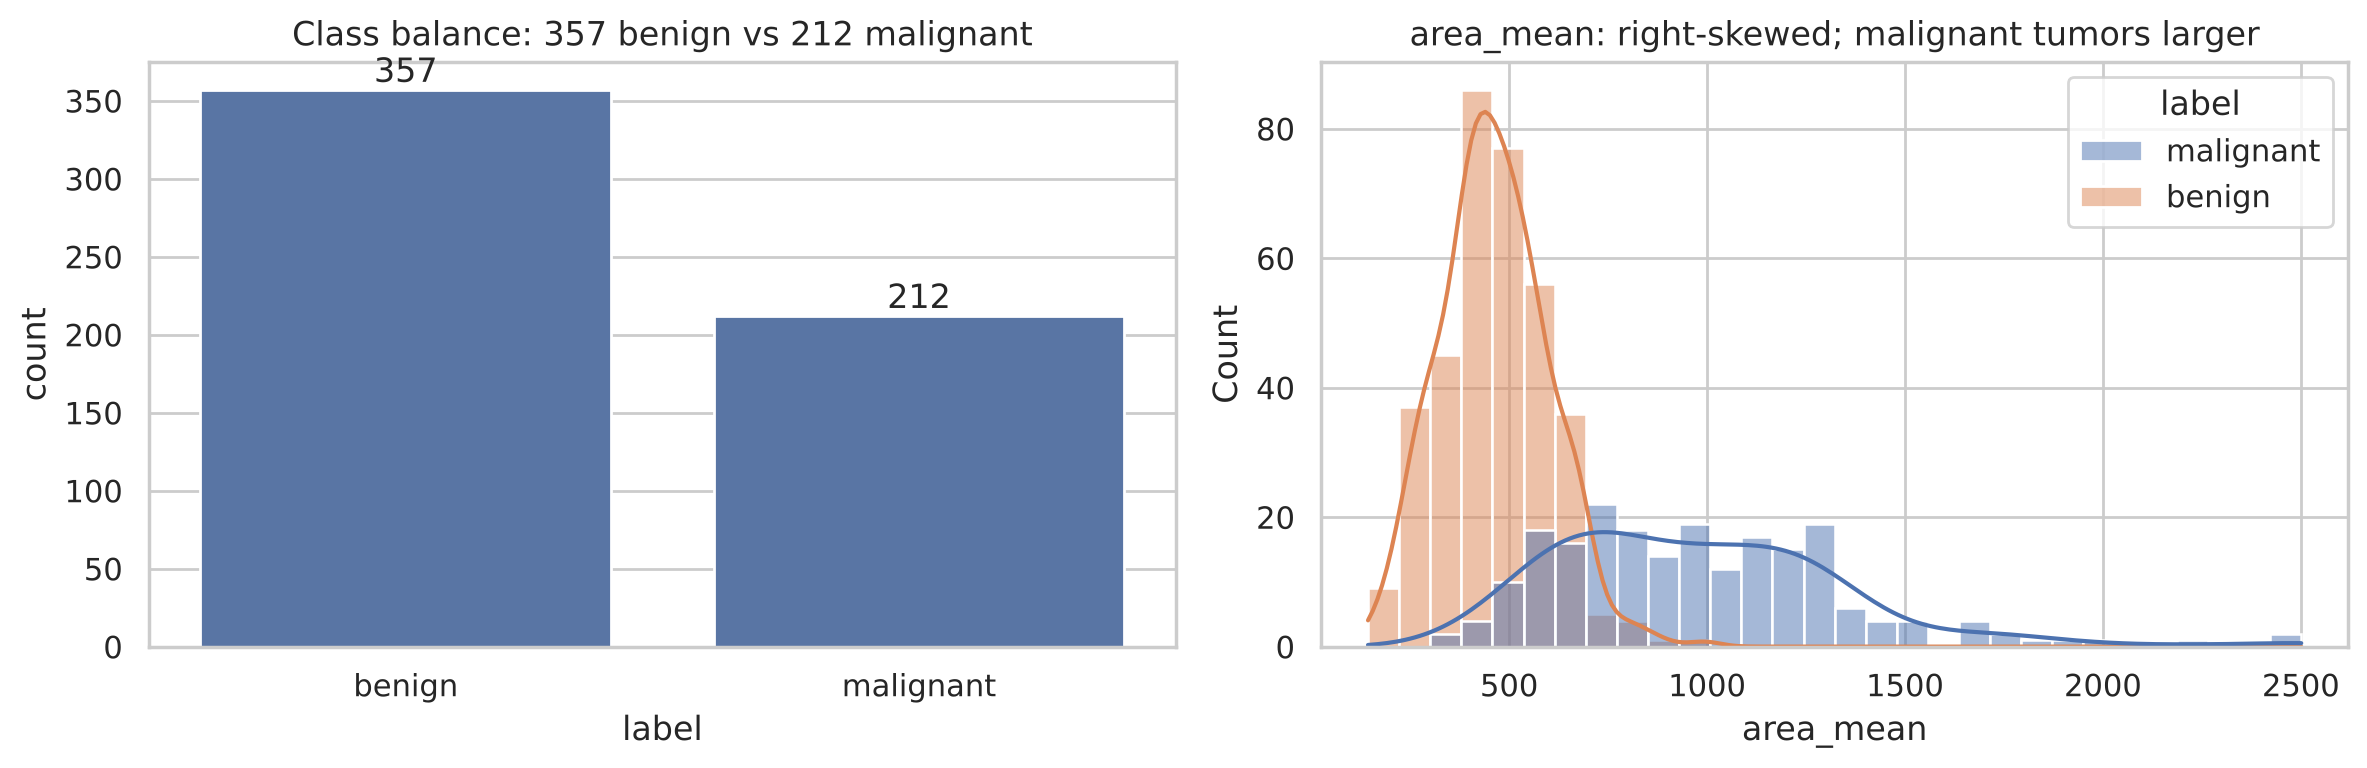

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x="label", data=eda, ax=axes[0], order=["benign", "malignant"])
axes[0].set_title("Class balance: 357 benign vs 212 malignant")
for b in axes[0].patches:
    axes[0].annotate(f"{b.get_height():.0f}", (b.get_x() + b.get_width() / 2, b.get_height()), ha="center", va="bottom")
sns.histplot(data=eda, x="area_mean", hue="label", kde=True, ax=axes[1], bins=30)
axes[1].set_title("area_mean: right-skewed; malignant tumors larger")
plt.tight_layout(); plt.show()

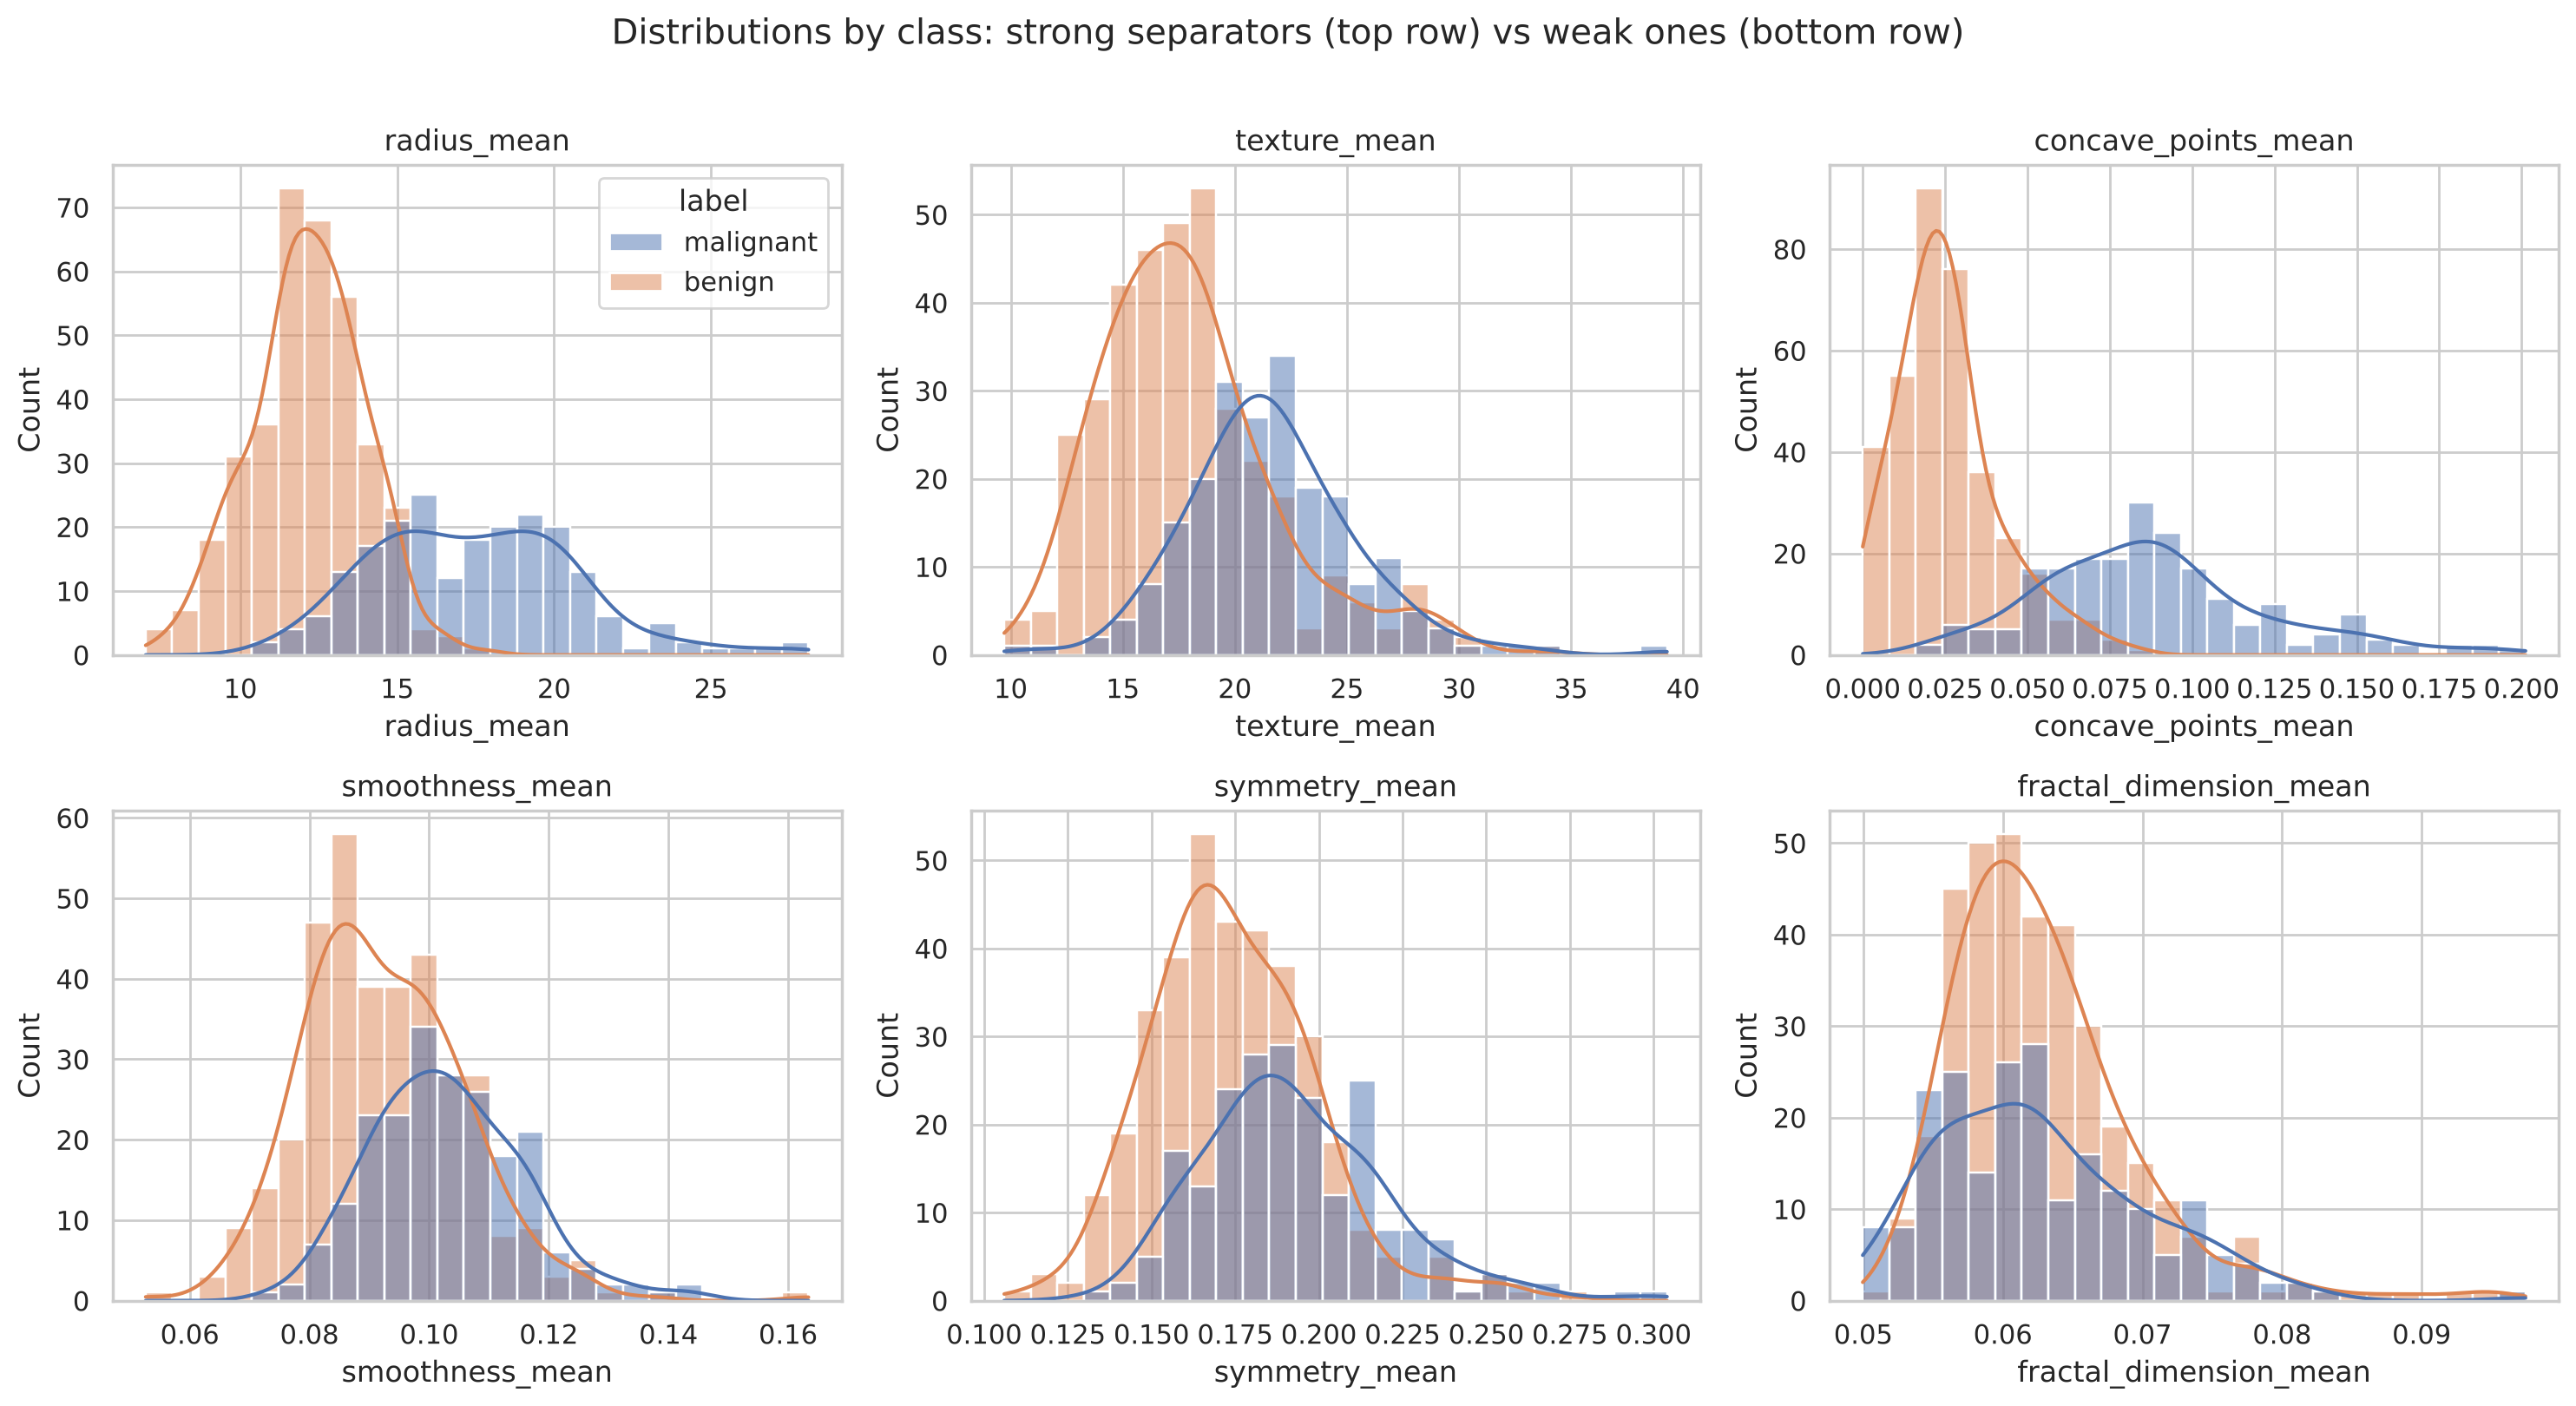

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, f in zip(axes.ravel(), ["radius_mean", "texture_mean", "concave_points_mean",
                                "smoothness_mean", "symmetry_mean", "fractal_dimension_mean"]):
    sns.histplot(data=eda, x=f, hue="label", kde=True, ax=ax, bins=25, legend=(f == "radius_mean"))
    ax.set_title(f)
plt.suptitle("Distributions by class: strong separators (top row) vs weak ones (bottom row)", y=1.01)
plt.tight_layout(); plt.show()

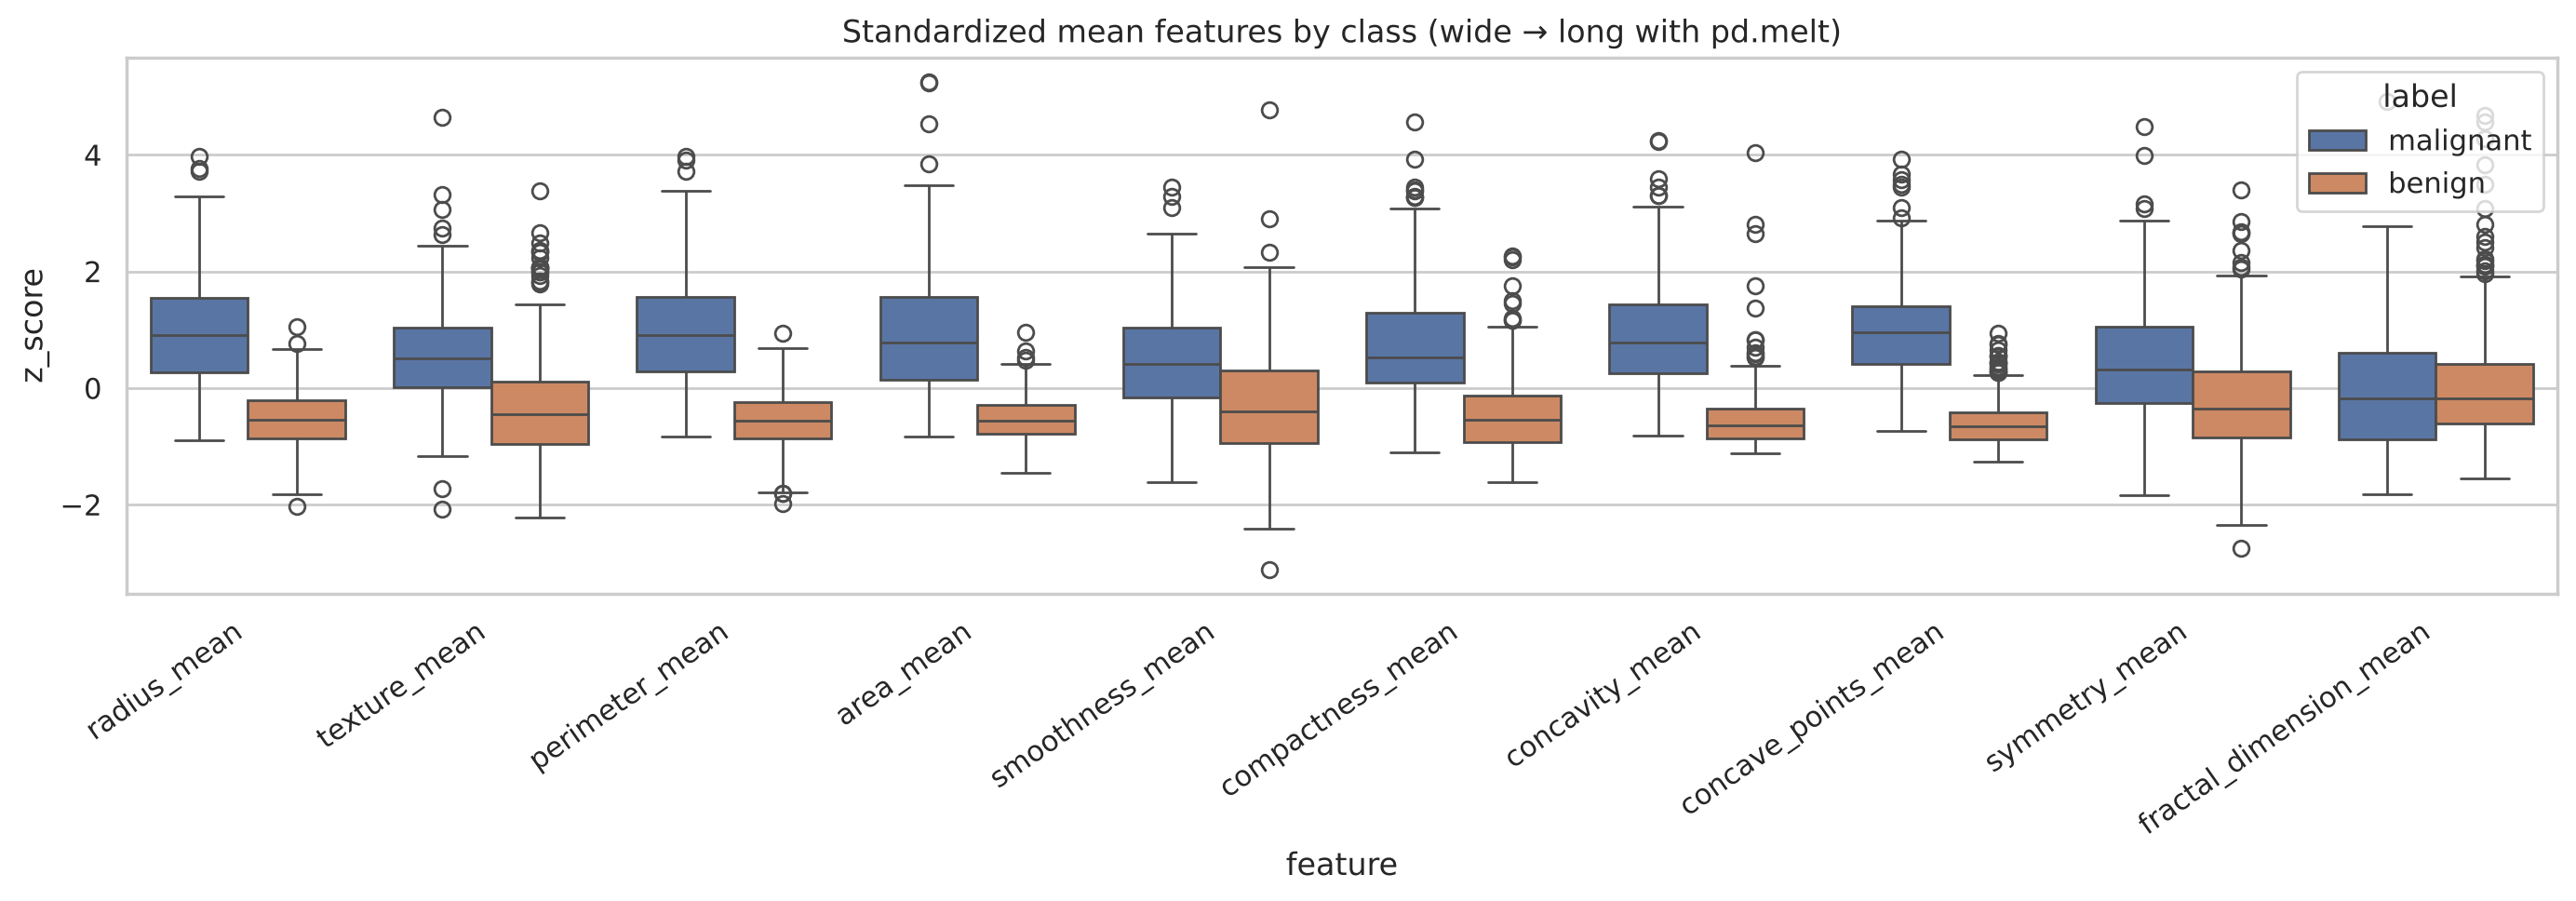

In [13]:
mean_cols = [f"{b}_mean" for b in BASE]
z = (eda[mean_cols] - eda[mean_cols].mean()) / eda[mean_cols].std()   # standardize so one axis fits all
long = pd.melt(z.assign(label=eda["label"]), id_vars="label", var_name="feature", value_name="z_score")
plt.figure(figsize=(14, 5))
sns.boxplot(data=long, x="feature", y="z_score", hue="label")
plt.xticks(rotation=35, ha="right"); plt.title("Standardized mean features by class (wide → long with pd.melt)")
plt.tight_layout(); plt.show()

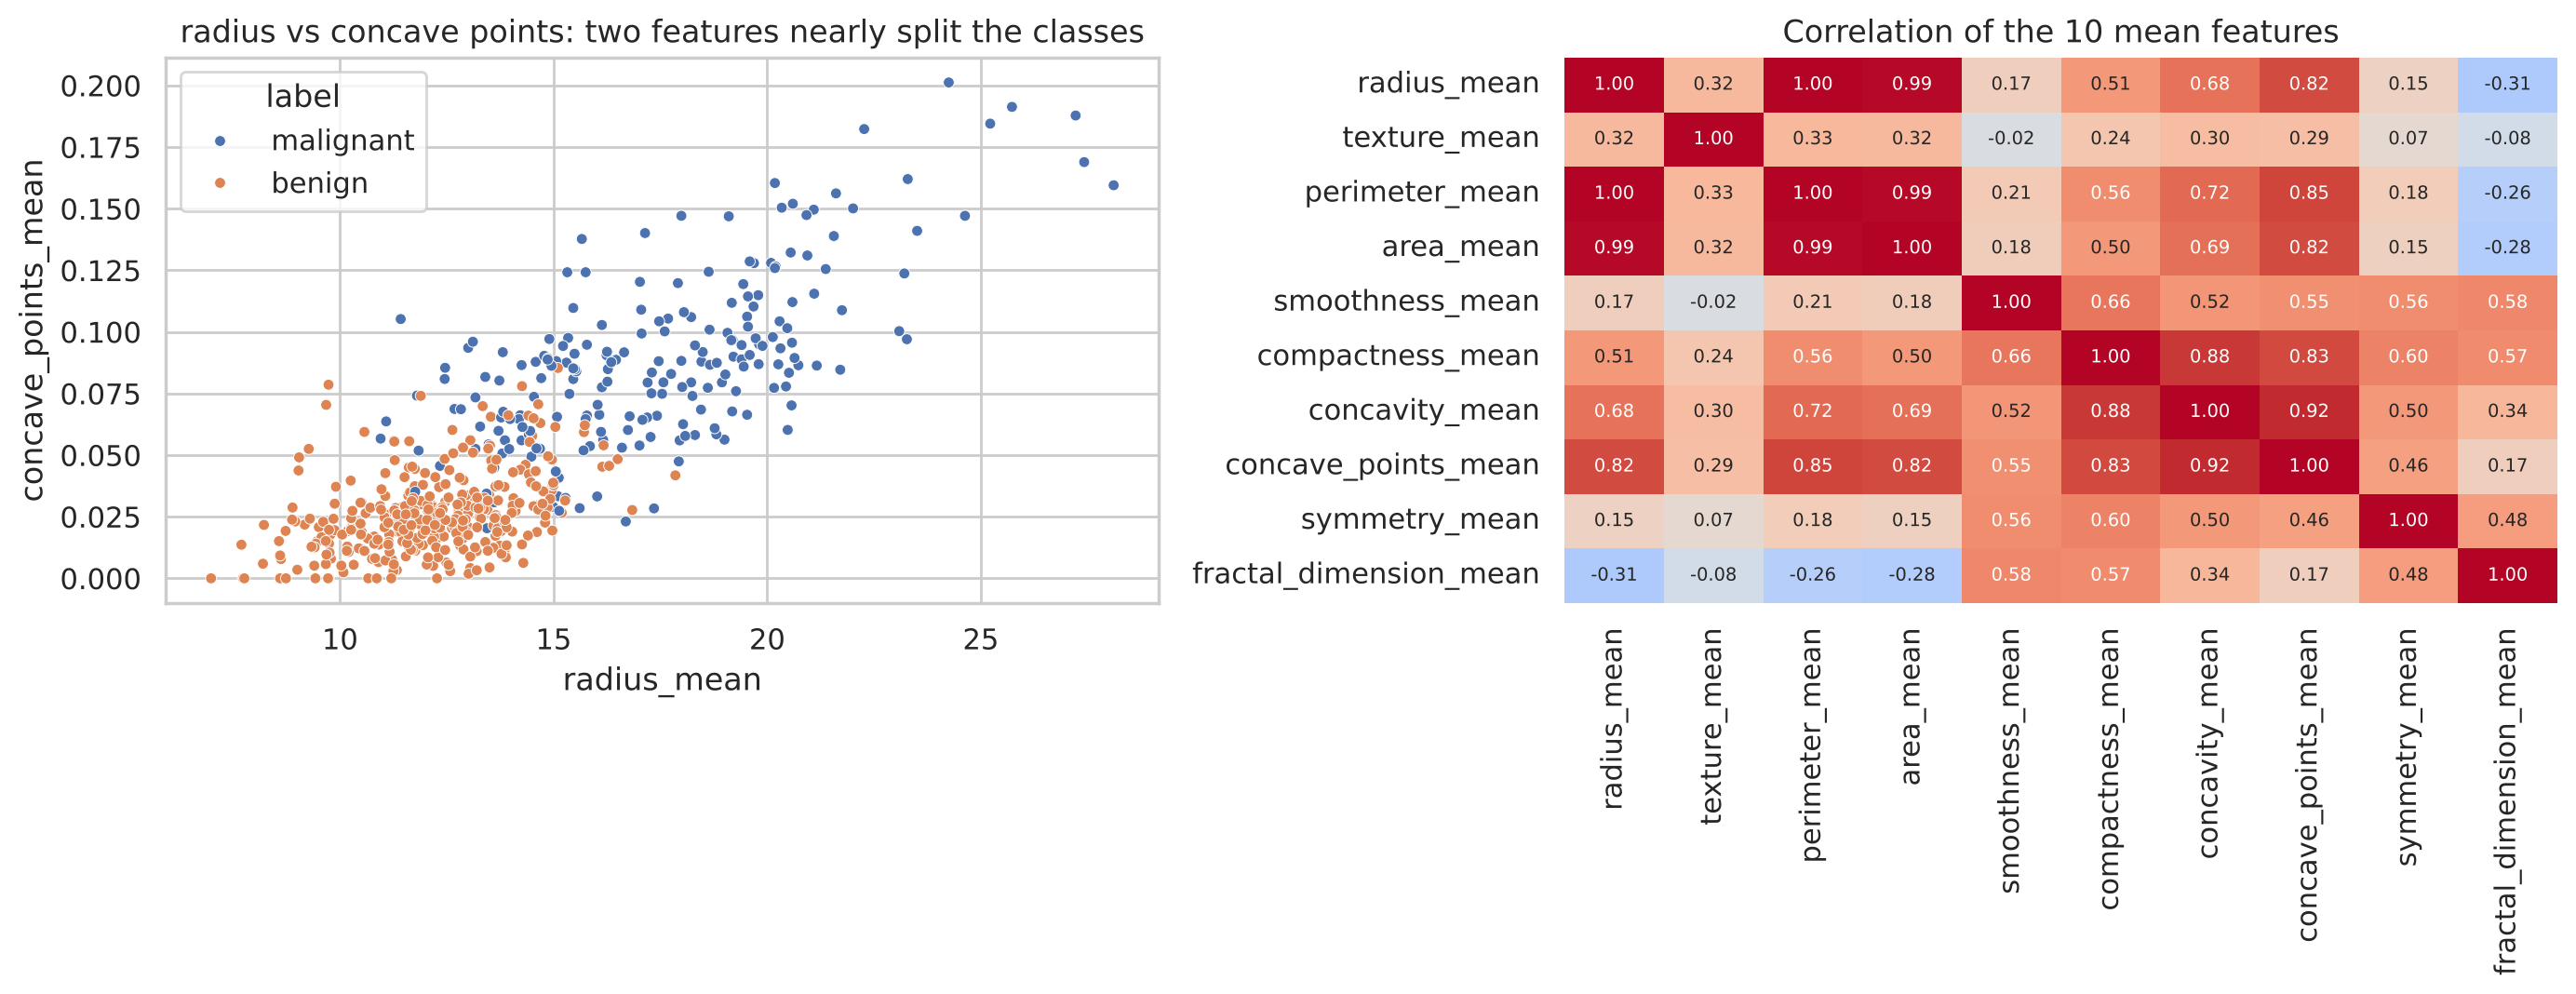

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.scatterplot(data=eda, x="radius_mean", y="concave_points_mean", hue="label", s=18, ax=axes[0])
axes[0].set_title("radius vs concave points: two features nearly split the classes")
sns.heatmap(clean[mean_cols].corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f",
            annot_kws={"size": 7}, ax=axes[1], cbar=False)
axes[1].set_title("Correlation of the 10 mean features")
plt.tight_layout(); plt.show()

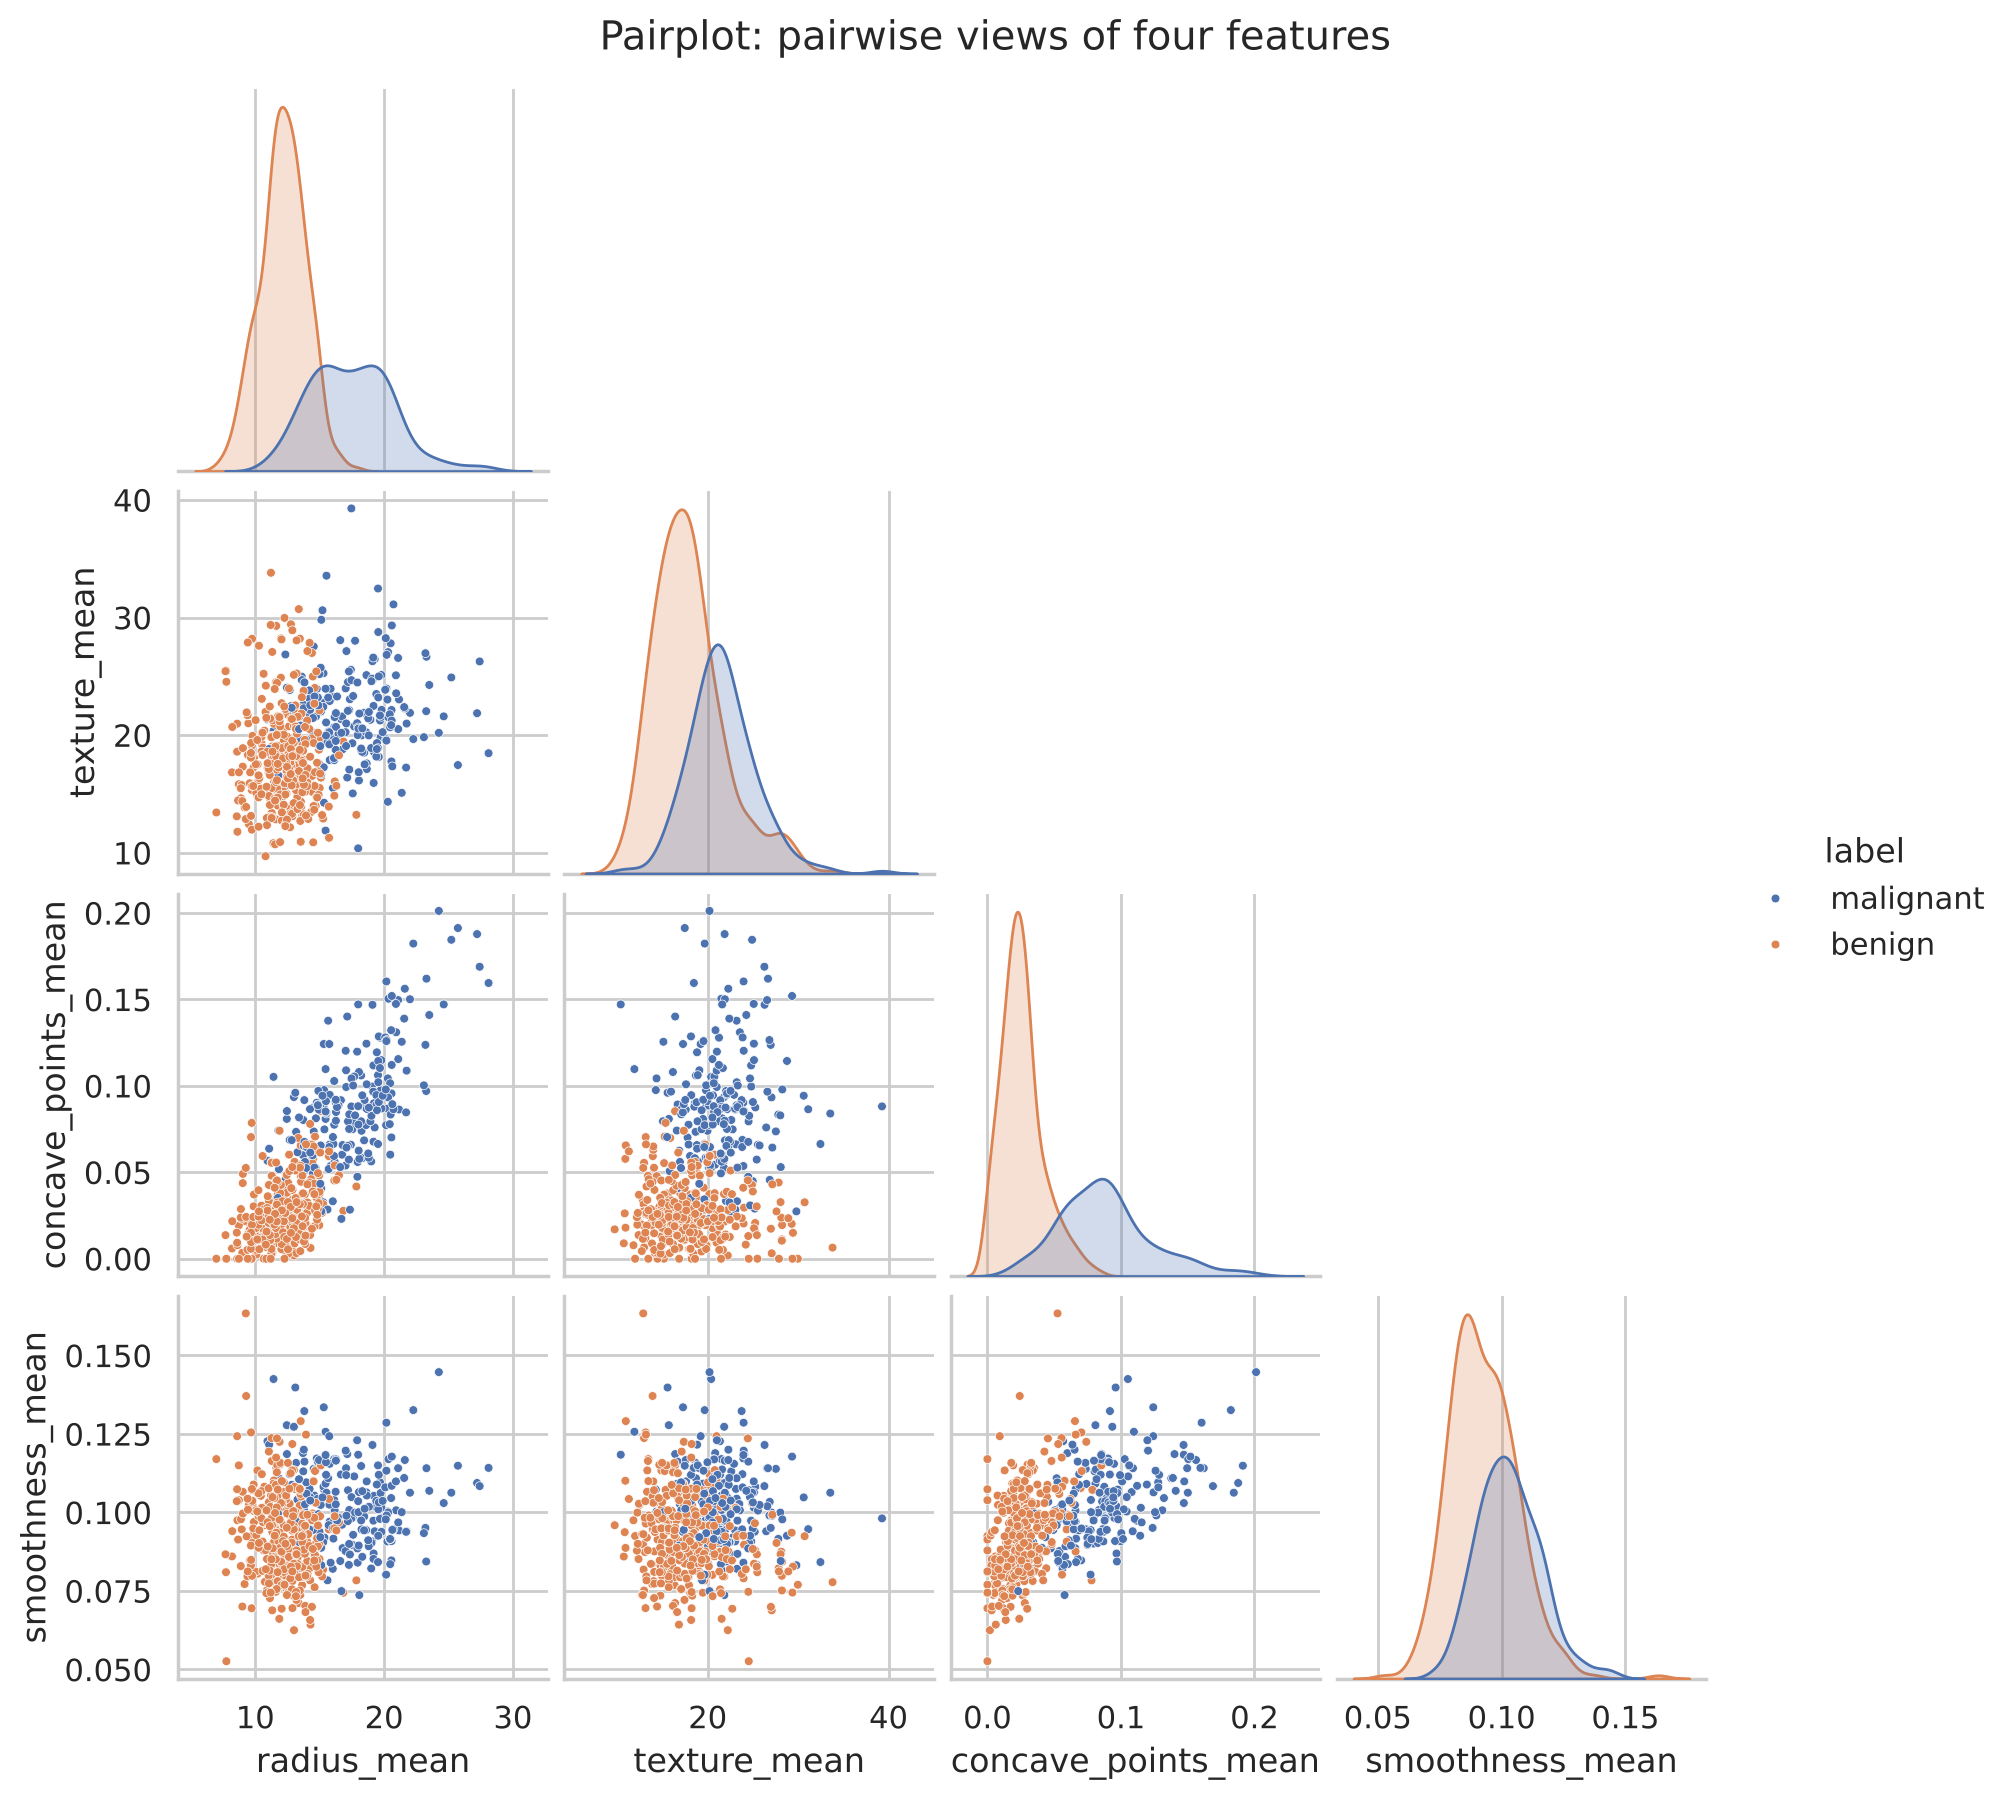

In [15]:
g = sns.pairplot(eda[["radius_mean", "texture_mean", "concave_points_mean", "smoothness_mean", "label"]],
                 hue="label", corner=True, plot_kws={"s": 10}, height=2.2)
g.figure.suptitle("Pairplot: pairwise views of four features", y=1.02)
plt.show()

**Findings from the visuals:**
- **Imbalance:** 63/37 → stratify the split and judge models on recall/precision, not accuracy.
- **Separation:** radius, area, perimeter, and concave points separate the classes clearly; smoothness, symmetry, and fractal dimension overlap heavily.
- **Skew and outliers:** area is right-skewed with long malignant tails; outliers are large real tumors, not errors, so they are kept.
- **Correlation:** radius, perimeter, and area are ~1.0 correlated, and concavity measures cluster together. Expect redundancy.
- **Two features nearly do it alone:** radius vs concave points shows an almost clean split, which is why a simple linear model will be competitive.

## 7. SQL inside the notebook: `ROW_NUMBER()` and friends

`sqlite3` loads a DataFrame into an in-memory table, so the same data can be checked with SQL. Every query is matched with its pandas equivalent, and an `assert` proves they agree.

**`ROW_NUMBER() OVER (PARTITION BY a ORDER BY b)`** numbers rows 1, 2, 3, … within each group of `a`, in the order of `b`, **with no ties**. Classic uses: top-N per group, and de-duplication (keep `rn = 1`).

| Function | Ties get | Sequence for values 10, 10, 8 |
|---|---|---|
| `ROW_NUMBER()` | different numbers | 1, 2, 3 |
| `RANK()` | same number, then a gap | 1, 1, 3 |
| `DENSE_RANK()` | same number, no gap | 1, 1, 2 |

In [16]:
con = sqlite3.connect(":memory:")
(eda[["id", TARGET, "label", "radius_mean", "area_mean", "concave_points_mean", "size_band"]]
    .assign(size_band=lambda d: d["size_band"].astype(str))
    .to_sql("tumors", con, index=False))

def sql(q: str) -> pd.DataFrame:
    return pd.read_sql(q, con)

print("GROUP BY: class profile")
display(sql("""
    SELECT label, COUNT(*) AS n, ROUND(AVG(area_mean), 1) AS avg_area, ROUND(MAX(area_mean), 1) AS max_area
    FROM tumors GROUP BY label ORDER BY label
"""))

GROUP BY: class profile


,label,n,avg_area,max_area
0,benign,357,462.8,992.1
1,malignant,212,978.4,2501.0


In [17]:
top3_sql = sql("""
    SELECT id, label, area_mean, rn
    FROM (
        SELECT id, label, area_mean,
               ROW_NUMBER() OVER (PARTITION BY label ORDER BY area_mean DESC) AS rn
        FROM tumors
    )
    WHERE rn <= 3
    ORDER BY label, rn
""")
print("ROW_NUMBER: 3 largest tumors in each class")
display(top3_sql)

# pandas equivalent: sort, then number within each group with cumcount
t = eda.sort_values(["label", "area_mean"], ascending=[True, False]).copy()
t["rn"] = t.groupby("label").cumcount() + 1
top3_pd = t.loc[t["rn"] <= 3, ["id", "label", "area_mean", "rn"]].reset_index(drop=True)
assert top3_pd["id"].tolist() == top3_sql["id"].tolist(), "SQL and pandas disagree"
print("pandas groupby().cumcount() + 1 matches SQL ROW_NUMBER")

ROW_NUMBER: 3 largest tumors in each class


,id,label,area_mean,rn
0,842793,benign,992.1,1
1,842459,benign,880.2,2
2,842665,benign,838.1,3
3,842763,malignant,2501.0,1
4,842514,malignant,2499.0,2
5,842482,malignant,2250.0,3


pandas groupby().cumcount() + 1 matches SQL ROW_NUMBER


In [18]:
print("ROW_NUMBER vs RANK vs DENSE_RANK on radius rounded to whole numbers (ties!)")
ranks_sql = sql("""
    SELECT id, ROUND(radius_mean) AS r,
           ROW_NUMBER() OVER (ORDER BY ROUND(radius_mean) DESC, id) AS row_num,
           RANK()       OVER (ORDER BY ROUND(radius_mean) DESC)     AS rnk,
           DENSE_RANK() OVER (ORDER BY ROUND(radius_mean) DESC)     AS dense_rnk
    FROM tumors
    ORDER BY row_num
    LIMIT 8
""")
display(ranks_sql)

r = eda[["id"]].assign(r=eda["radius_mean"].round()).sort_values(["r", "id"], ascending=[False, True])
r["rnk"] = r["r"].rank(method="min", ascending=False).astype(int)        # RANK
r["dense_rnk"] = r["r"].rank(method="dense", ascending=False).astype(int)  # DENSE_RANK
assert r.head(8)["rnk"].tolist() == ranks_sql["rnk"].tolist()
assert r.head(8)["dense_rnk"].tolist() == ranks_sql["dense_rnk"].tolist()
print("pandas rank(method='min') = RANK, rank(method='dense') = DENSE_RANK")

ROW_NUMBER vs RANK vs DENSE_RANK on radius rounded to whole numbers (ties!)


,id,r,row_num,rnk,dense_rnk
0,842514,28.0,1,1,1
1,842482,27.0,2,2,2
2,842763,27.0,3,2,2
3,842654,26.0,4,4,3
4,842384,25.0,5,5,4
5,842823,25.0,6,5,4
6,842424,24.0,7,7,5
7,842641,24.0,8,7,5


pandas rank(method='min') = RANK, rank(method='dense') = DENSE_RANK


In [19]:
# De-duplication: a feed that re-sent some records with a later load time. Keep the latest per id.
feed = eda[["id", "area_mean"]].head(6).assign(loaded_at="2026-11-01")
resent = feed.head(2).assign(area_mean=lambda d: d["area_mean"] + 1.0, loaded_at="2026-11-15")
pd.concat([feed, resent]).to_sql("feed", con, index=False)

dedup_sql = sql("""
    WITH ranked AS (
        SELECT *, ROW_NUMBER() OVER (PARTITION BY id ORDER BY loaded_at DESC) AS rn
        FROM feed
    )
    SELECT id, area_mean, loaded_at FROM ranked WHERE rn = 1 ORDER BY id
""")
print(f"feed rows: {len(feed) + len(resent)} -> after dedup: {len(dedup_sql)}")
display(dedup_sql)

dedup_pd = (pd.concat([feed, resent]).sort_values("loaded_at", ascending=False)
              .drop_duplicates("id").sort_values("id").reset_index(drop=True))
assert dedup_pd["id"].tolist() == dedup_sql["id"].tolist()
assert (dedup_pd["loaded_at"] == dedup_sql["loaded_at"]).all()
con.close()

feed rows: 8 -> after dedup: 6


,id,area_mean,loaded_at
0,842302,1002.0,2026-11-15
1,842303,1327.0,2026-11-15
2,842304,1203.0,2026-11-01
3,842305,386.1,2026-11-01
4,842306,1297.0,2026-11-01
5,842307,477.1,2026-11-01


## 8. Split the data: stratified 60 / 20 / 20

- **Train (60%)** fits the models. **Validation (20%)** picks the model and the threshold. **Test (20%)** is touched once, at the end.
- **`stratify=y`** keeps the 37% malignant share identical in all three; without it a small test set can drift by several points by chance.
- Split **before** any fitted preprocessing, so nothing learned from val/test leaks into training.
- Only the 30 original features go in. EDA-only columns (bands, ratios, labels) stay in `eda`.

In [20]:
X = clean[FEATURES]
y = clean[TARGET].to_numpy()

X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, stratify=y_temp,
                                                  random_state=SEED)   # 0.25 of 80% = 20% overall

split_table = pd.DataFrame({
    "rows": [len(y_train), len(y_val), len(y_test)],
    "malignant": [y_train.sum(), y_val.sum(), y_test.sum()],
    "malignant_share": [y_train.mean(), y_val.mean(), y_test.mean()],
}, index=["train", "val", "test"]).round(3)
display(split_table)

assert len(y_train) + len(y_val) + len(y_test) == len(y)
assert set(X_train.index).isdisjoint(X_val.index) and set(X_train.index).isdisjoint(X_test.index)
assert (split_table["malignant_share"] - y.mean()).abs().max() < 0.01, "stratification failed"

,rows,malignant,malignant_share
train,341,127,0.372
val,114,43,0.377
test,114,42,0.368


## 9. Preprocess with no leakage

One `Pipeline` (impute → scale) is fit on **train only**, then applied to validation and test. The imputer is a guardrail: the clean data has no nulls, but a future batch might (Section 15).

In [21]:
prep = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
Xtr = prep.fit_transform(X_train)     # learn medians, means and stds from train
Xva = prep.transform(X_val)           # reuse them
Xte = prep.transform(X_test)

assert np.allclose(Xtr.mean(axis=0), 0, atol=1e-9) and np.allclose(Xtr.std(axis=0), 1, atol=1e-9)
print("train means ~0, stds ~1 | val mean of means:", Xva.mean().round(3), "(not exactly 0: expected)")

train means ~0, stds ~1 | val mean of means: 0.046 (not exactly 0: expected)


## 10. Models: baselines with leak-free cross-validation

Always beat something simple first. Cross-validation runs on the **raw** training rows with the imputer and scaler **inside** the pipeline, so each fold's preprocessing is learned only from that fold's training part. Running CV on already-scaled `Xtr` would leak the held-out fold's mean and standard deviation into training.

- **Logistic regression:** linear, fast, interpretable, L2-regularized by default.
- **Decision tree:** interpretable rules, but high variance (shown for contrast, not a candidate).
- **Random forest:** many bootstrapped trees on random feature subsets → much lower variance.

In [22]:
def scores(name, y_true, prob, threshold=0.5):
    pred = (prob >= threshold).astype(int)
    return {"model": name, "threshold": round(float(threshold), 3),
            "recall": round(recall_score(y_true, pred), 3),
            "precision": round(precision_score(y_true, pred, zero_division=0), 3),
            "f1": round(f1_score(y_true, pred), 3),
            "roc_auc": round(roc_auc_score(y_true, prob), 3)}

logreg = LogisticRegression(max_iter=5000, class_weight="balanced")
tree = DecisionTreeClassifier(class_weight="balanced", random_state=SEED)    # unbounded depth on purpose
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight="balanced", random_state=SEED)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_rows = []
for name, est in [("logistic regression", logreg), ("decision tree", tree), ("random forest", rf)]:
    pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), est)
    auc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc")
    rec = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="recall")
    cv_rows.append({"model": name, "cv_roc_auc": f"{auc.mean():.3f} ± {auc.std():.3f}",
                    "cv_recall": f"{rec.mean():.3f} ± {rec.std():.3f}"})
display(pd.DataFrame(cv_rows))

logreg.fit(Xtr, y_train); tree.fit(Xtr, y_train); rf.fit(Xtr, y_train)
print("decision tree: train accuracy", tree.score(Xtr, y_train), "vs val accuracy", round(tree.score(Xva, y_val), 3),
      f"(depth {tree.get_depth()}: memorized the training set)")
val_rows = [scores("logistic regression", y_val, logreg.predict_proba(Xva)[:, 1]),
            scores("random forest", y_val, rf.predict_proba(Xva)[:, 1])]
display(pd.DataFrame(val_rows))

,model,cv_roc_auc,cv_recall
0,logistic regression,0.994 ± 0.008,0.953 ± 0.038
1,decision tree,0.941 ± 0.020,0.929 ± 0.051
2,random forest,0.987 ± 0.011,0.938 ± 0.052


decision tree: train accuracy 1.0 vs val accuracy 0.956 (depth 7: memorized the training set)


,model,threshold,recall,precision,f1,roc_auc
0,logistic regression,0.5,0.977,0.955,0.966,0.996
1,random forest,0.5,0.953,0.953,0.953,0.992


## 11. Keras binary classifier: overfitting vs Dropout

- **Output:** one sigmoid unit = P(malignant). **Loss:** binary cross-entropy (log loss for a yes/no outcome).
- **Model A** is deliberately oversized with no regularization and trains for 200 epochs: watch validation loss turn upward while training loss keeps falling. That gap is overfitting.
- **Model B** is smaller, adds **Dropout** (randomly zeroes 30% of units each step), and uses **EarlyStopping** to keep the weights from the best validation epoch.

E0000 00:00:1795203281.795327   17594 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


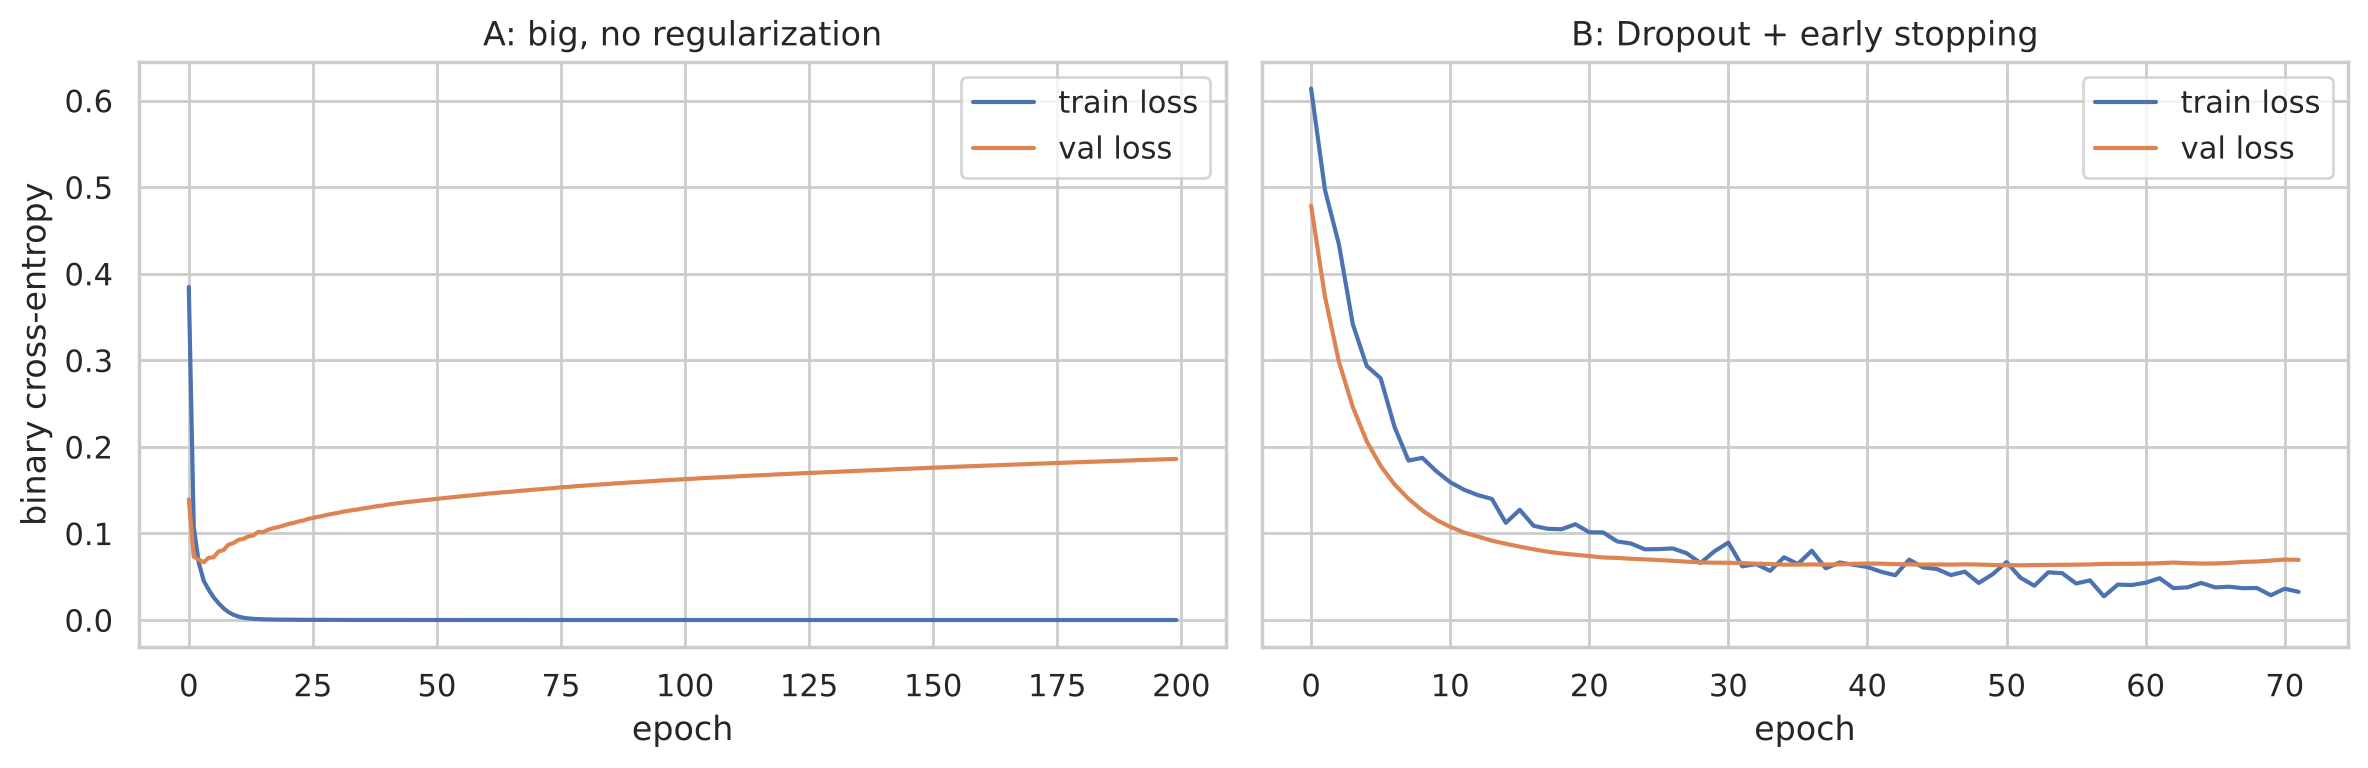

A: best val loss 0.067 at epoch 3, final val loss 0.186 (rising = overfitting)
B: stopped after 72 epochs, best val loss 0.063


In [23]:
def build_model(hidden, dropout=0.0):
    model = keras.Sequential([layers.Input(shape=(Xtr.shape[1],))])
    for units in hidden:
        model.add(layers.Dense(units, activation="relu"))
        if dropout:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1, activation="sigmoid"))
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy",
                  metrics=[keras.metrics.AUC(name="auc"), keras.metrics.Recall(name="recall")])
    return model

model_a = build_model([256, 256, 128])
hist_a = model_a.fit(Xtr, y_train, validation_data=(Xva, y_val), epochs=200, batch_size=32, verbose=0)

model_b = build_model([32, 16], dropout=0.3)
early = keras.callbacks.EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True)
hist_b = model_b.fit(Xtr, y_train, validation_data=(Xva, y_val), epochs=300, batch_size=32,
                     callbacks=[early], verbose=0)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, h, title in [(axes[0], hist_a, "A: big, no regularization"), (axes[1], hist_b, "B: Dropout + early stopping")]:
    ax.plot(h.history["loss"], label="train loss"); ax.plot(h.history["val_loss"], label="val loss")
    ax.set_title(title); ax.set_xlabel("epoch"); ax.legend()
axes[0].set_ylabel("binary cross-entropy")
plt.tight_layout(); plt.show()

best_a = int(np.argmin(hist_a.history["val_loss"]))
print(f"A: best val loss {min(hist_a.history['val_loss']):.3f} at epoch {best_a}, "
      f"final val loss {hist_a.history['val_loss'][-1]:.3f} (rising = overfitting)")
print(f"B: stopped after {len(hist_b.history['loss'])} epochs, best val loss {min(hist_b.history['val_loss']):.3f}")

## 12. Validate model outputs

Order matters: **tune every candidate's threshold on validation → apply the selection rule from Section 0 on validation → touch test once.** Comparing models at different thresholds (one tuned, the others at 0.5) is not a fair comparison, so every model gets its own validation-tuned threshold. Model A was the overfitting demo, so it is not a candidate.

In [24]:
predictors = {   # dict order = simplest first, used as the tie-break
    "logistic regression": lambda X: logreg.predict_proba(X)[:, 1],
    "random forest": lambda X: rf.predict_proba(X)[:, 1],
    "Keras B": lambda X: model_b.predict(X, verbose=0).ravel(),
}
TARGET_RECALL = 0.97

def check_probs(prob, n_rows, name):
    """Sanity checks on outputs before trusting any metric."""
    assert prob.shape == (n_rows,), f"{name}: expected {n_rows} predictions, got {prob.shape}"
    assert np.isfinite(prob).all(), f"{name}: NaN or inf in model output"
    assert ((prob >= 0) & (prob <= 1)).all(), f"{name}: probabilities out of range"

def tune_threshold(y_true, prob, target_recall=TARGET_RECALL):
    """Highest threshold that still catches >= target_recall of malignant cases, capped at 0.5 for a cancer screen."""
    _, rec, thr = precision_recall_curve(y_true, prob)
    ok = np.where(rec[:-1] >= target_recall)[0]
    return min(float(thr[ok].max()), 0.5) if len(ok) else 0.5

val_probs, thresholds = {}, {}
for name, predict_fn in predictors.items():
    p = predict_fn(Xva)
    check_probs(p, len(y_val), name)
    val_probs[name], thresholds[name] = p, tune_threshold(y_val, p)

val_table = pd.DataFrame([scores(n, y_val, p, thresholds[n]) for n, p in val_probs.items()])
val_table

,model,threshold,recall,precision,f1,roc_auc
0,logistic regression,0.500,0.977,0.955,0.966,0.996
1,random forest,0.337,0.977,0.840,0.903,0.992
2,Keras B,0.500,0.977,0.977,0.977,0.996


In [25]:
# Apply the selection rule from Section 0 (on validation only)
meets = val_table[val_table["recall"] >= TARGET_RECALL]
pool = meets if len(meets) else val_table[val_table["recall"] == val_table["recall"].max()]
chosen_name = pool.sort_values("precision", ascending=False, kind="stable").iloc[0]["model"]
chosen_thr = thresholds[chosen_name]
print(f"chosen model: {chosen_name} @ threshold {chosen_thr:.3f}")

# Threshold sweep for the chosen model, to show the recall/precision trade-off
pd.DataFrame([scores(chosen_name, y_val, val_probs[chosen_name], t) for t in sorted({0.2, 0.3, 0.5, chosen_thr})])

chosen model: Keras B @ threshold 0.500


,model,threshold,recall,precision,f1,roc_auc
0,Keras B,0.2,0.977,0.875,0.923,0.996
1,Keras B,0.3,0.977,0.933,0.955,0.996
2,Keras B,0.5,0.977,0.977,0.977,0.996


In [26]:
# One-time final evaluation on the untouched test set; every model at its own validation-tuned threshold
test_probs = {name: fn(Xte) for name, fn in predictors.items()}
for name, p in test_probs.items():
    check_probs(p, len(y_test), name)

prob_test = test_probs[chosen_name]
pred_test = (prob_test >= chosen_thr).astype(int)

cm = confusion_matrix(y_test, pred_test)
print(f"{chosen_name} @ {chosen_thr:.3f}  confusion matrix [[TN FP] [FN TP]]:\n", cm)
print(classification_report(y_test, pred_test, target_names=["benign", "malignant"], digits=3))

final = pd.DataFrame([scores(n, y_test, p, thresholds[n]) for n, p in test_probs.items()])
final

Keras B @ 0.500  confusion matrix [[TN FP] [FN TP]]:
 [[71  1]
 [ 1 41]]
              precision    recall  f1-score   support

      benign      0.986     0.986     0.986        72
   malignant      0.976     0.976     0.976        42

    accuracy                          0.982       114
   macro avg      0.981     0.981     0.981       114
weighted avg      0.982     0.982     0.982       114



,model,threshold,recall,precision,f1,roc_auc
0,logistic regression,0.500,0.976,0.953,0.965,0.995
1,random forest,0.337,1.000,0.933,0.966,0.998
2,Keras B,0.500,0.976,0.976,0.976,0.995


**Confidence intervals.** The test set has 114 tumors, about 42 of them malignant, so **one missed cancer moves recall by ~2.4 points**. A point estimate alone overstates how much we know. A bootstrap resamples the test rows with replacement 2,000 times and recomputes each metric; the middle 95% of those values is the interval.

In [27]:
rng = np.random.default_rng(SEED)
boot = {"recall": [], "precision": [], "roc_auc": []}
n = len(y_test)
for _ in range(2000):
    idx = rng.integers(0, n, n)
    yt, pt, pr = y_test[idx], pred_test[idx], prob_test[idx]
    if yt.sum() in (0, n) or pt.sum() == 0:      # metric undefined for this resample
        continue
    boot["recall"].append(recall_score(yt, pt))
    boot["precision"].append(precision_score(yt, pt))
    boot["roc_auc"].append(roc_auc_score(yt, pr))

ci = {k: np.percentile(v, [2.5, 97.5]) for k, v in boot.items()}
point = final.set_index("model").loc[chosen_name]
pd.DataFrame({"point": [point[k] for k in ci],
              "ci_low_2.5%": [ci[k][0] for k in ci],
              "ci_high_97.5%": [ci[k][1] for k in ci]}, index=list(ci)).round(3)

,point,ci_low_2.5%,ci_high_97.5%
recall,0.976,0.921,1.0
precision,0.976,0.919,1.0
roc_auc,0.995,0.983,1.0


In [28]:
# Did we meet the success criteria from Section 0?
for metric, bar in [("recall", 0.95), ("roc_auc", 0.97)]:
    print(f"{metric:8s} point {point[metric]:.3f} >= {bar}: {point[metric] >= bar} | "
          f"CI lower bound {ci[metric][0]:.3f} >= {bar}: {ci[metric][0] >= bar}")

recall   point 0.976 >= 0.95: True | CI lower bound 0.921 >= 0.95: False
roc_auc  point 0.995 >= 0.97: True | CI lower bound 0.983 >= 0.97: True


**How to read it:** if the point estimate passes but the CI lower bound does not, the honest statement is *"meets the target on this test set, but 114 tumors can't confirm it; we need a larger or external validation set."* That's a finding, not a failure.

## 13. Calibration: do the probabilities mean what they say?

ROC-AUC only checks **ranking**. If a reviewer sees "0.80", about 80% of tumors scored near 0.80 should actually be malignant. Two checks on the test set (used here for measurement only; no decisions are made from it):
- **Brier score:** mean squared error between the predicted probability and the 0/1 outcome. 0 is perfect. Compare it to a model that always predicts the training base rate.
- **Reliability curve:** bin predictions, then plot the mean predicted probability against the actual malignant rate in each bin. On the diagonal = calibrated.

logistic regression    0.0242
random forest          0.0263
Keras B                0.0166
base rate only         0.2327


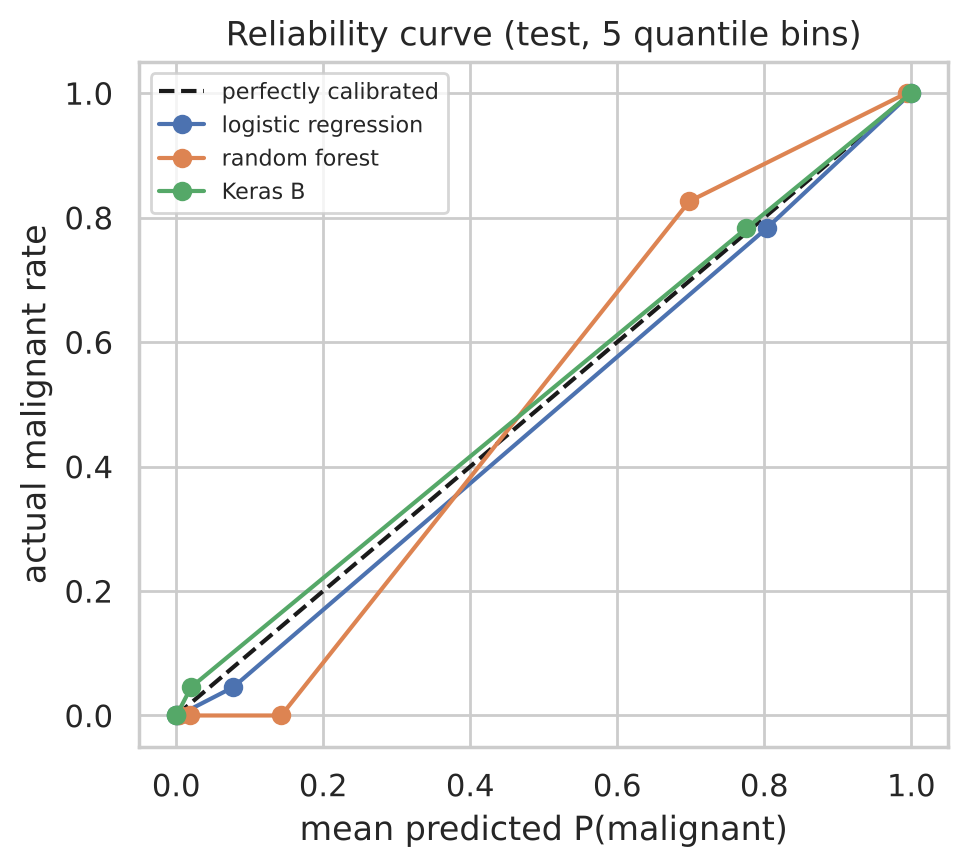

In [29]:
brier_ref = brier_score_loss(y_test, np.full(len(y_test), y_train.mean()))
brier = {n: brier_score_loss(y_test, p) for n, p in test_probs.items()}
print(pd.Series({**brier, "base rate only": brier_ref}, name="brier").round(4).to_string())

fig, ax = plt.subplots(figsize=(5, 4.5))
ax.plot([0, 1], [0, 1], "k--", label="perfectly calibrated")
for name, p in test_probs.items():
    frac_pos, mean_pred = calibration_curve(y_test, p, n_bins=5, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", label=name)
ax.set_xlabel("mean predicted P(malignant)"); ax.set_ylabel("actual malignant rate")
ax.set_title("Reliability curve (test, 5 quantile bins)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**What to say:** a Brier score far below the base-rate guess means the probabilities carry real information. Random forest usually bends away from the diagonal at the ends, because averaging many trees rarely produces probabilities near 0 or 1. With 5 bins of ~23 tumors each, treat the curve as a coarse check.

`class_weight="balanced"` can also push probabilities toward malignant, because it trains as if the classes were equally common. For this use (rank the queue, flag above a threshold), ranking and the validation-tuned threshold are what matter. If reviewers will see the probability itself and the curve is off, recalibrate on validation (`CalibratedClassifierCV` with `method="sigmoid"`; in scikit-learn ≥ 1.6, wrap the fitted model in `FrozenEstimator`) and recheck the Brier score.

## 14. What drives the predictions

**Permutation importance:** shuffle a feature on validation and measure how much ROC-AUC drops. It works for any model, including the network. Because radius, perimeter, and area are 0.98+ correlated (Section 5g), shuffling one alone barely hurts: the other two carry the same information. So we shuffle **measurement groups together** (all mean/se/worst versions, with radius/perimeter/area as one "size" group).

In [30]:
GROUPS = {"size (radius/perimeter/area)": [f for f in FEATURES if f.split("_")[0] in ("radius", "perimeter", "area")]}
for b in BASE:
    if b not in ("radius", "perimeter", "area"):
        GROUPS[b] = [f"{b}_{s}" for s in ("mean", "se", "worst")]

def grouped_permutation_importance(predict_fn, X, y, groups, n_repeats=20, seed=SEED):
    rng = np.random.default_rng(seed)
    base = roc_auc_score(y, predict_fn(X))
    out = {}
    for g, cols in groups.items():
        j = [FEATURES.index(c) for c in cols]
        drops = []
        for _ in range(n_repeats):
            Xp = X.copy()
            Xp[:, j] = Xp[rng.permutation(len(Xp))][:, j]   # same row shuffle for the whole group
            drops.append(base - roc_auc_score(y, predict_fn(Xp)))
        out[g] = (np.mean(drops), np.std(drops))
    return pd.DataFrame(out, index=["auc_drop_mean", "auc_drop_std"]).T.sort_values("auc_drop_mean", ascending=False)

imp = grouped_permutation_importance(predictors[chosen_name], Xva, y_val, GROUPS)
imp.round(4)

,auc_drop_mean,auc_drop_std
size (radius/perimeter/area),0.1857,0.0404
texture,0.0069,0.0041
smoothness,0.0045,0.0039
symmetry,0.0026,0.0017
concave_points,0.0025,0.0035
compactness,0.0016,0.0018
fractal_dimension,0.0015,0.0015
concavity,0.0001,0.0015


## 15. Score a new batch with integrity checks

A pipeline is end to end when a **new batch** can go in and scores come out safely. `score_batch` reuses the fitted `prep` and the chosen model/threshold, and:
- **rejects** batches that would silently produce wrong scores: missing ID or feature columns, duplicate IDs, text in numeric columns, negative sizes;
- **warns** on fixable issues: extra columns (ignored), missing values (median-imputed from training);
- **flags** rows outside the training range, which are scored but deserve a closer look;
- returns **IDs and scores only**, not the raw features. In real clinical use, the IDs would be references to the record, and flagged cases go to a human reviewer.

In [31]:
log = logging.getLogger("bc_scoring")
TRAIN_MIN, TRAIN_MAX = X_train.min(), X_train.max()

class SchemaError(ValueError):
    """Raised when a batch can't be scored safely."""

def score_batch(batch: pd.DataFrame, id_col: str = "sample_id") -> pd.DataFrame:
    if id_col not in batch.columns:
        raise SchemaError(f"missing id column '{id_col}'")
    if batch[id_col].duplicated().any():
        raise SchemaError("duplicate sample IDs")
    missing = [c for c in FEATURES if c not in batch.columns]
    if missing:
        raise SchemaError(f"missing feature columns: {missing}")
    extra = sorted(set(batch.columns) - set(FEATURES) - {id_col})
    if extra:
        log.warning("ignoring extra columns: %s", extra)

    X_new = batch[FEATURES]
    non_numeric = [c for c in FEATURES if not pd.api.types.is_numeric_dtype(X_new[c])]
    if non_numeric:
        raise SchemaError(f"non-numeric feature columns: {non_numeric}")
    if (X_new < 0).any().any():
        raise SchemaError("negative measurement found (sizes can't be negative)")
    n_missing = int(X_new.isna().sum().sum())
    if n_missing:
        log.warning("%d missing values will be median-imputed from training data", n_missing)

    outside = ((X_new < TRAIN_MIN) | (X_new > TRAIN_MAX)).any(axis=1)
    prob = predictors[chosen_name](prep.transform(X_new))
    check_probs(prob, len(batch), chosen_name)

    result = pd.DataFrame({id_col: batch[id_col].to_numpy(),
                           "p_malignant": prob.round(4),
                           "flag_for_review": prob >= chosen_thr,
                           "outside_training_range": outside.to_numpy()})
    log.info("scored batch model=%s threshold=%.3f rows=%d flagged=%d outside_range=%d",
             chosen_name, chosen_thr, len(result), int(result["flag_for_review"].sum()),
             int(result["outside_training_range"].sum()))
    return result

In [32]:
# A "new" batch: 6 test rows with synthetic IDs; one value pushed beyond the training max
new_batch = X_test.head(6).reset_index(drop=True)
new_batch.insert(0, "sample_id", [f"S-{i:04d}" for i in range(len(new_batch))])
new_batch.loc[0, "area_worst"] = TRAIN_MAX["area_worst"] * 1.5

scored = score_batch(new_batch)
assert len(scored) == len(new_batch)
assert bool(scored.loc[0, "outside_training_range"]), "out-of-range row was not flagged"
assert set(scored.columns) == {"sample_id", "p_malignant", "flag_for_review", "outside_training_range"}
scored

2026-11-20 14:35:29,109 INFO bc_scoring scored batch model=Keras B threshold=0.500 rows=6 flagged=2 outside_range=1


,sample_id,p_malignant,flag_for_review,outside_training_range
0,S-0000,0.2879,False,True
1,S-0001,1.0000,True,False
2,S-0002,0.0162,False,False
3,S-0003,0.8360,True,False
4,S-0004,0.2695,False,False
5,S-0005,0.0001,False,False


In [33]:
# Bad batches must fail loudly, not score silently
bad_batches = {
    "missing column": new_batch.drop(columns="radius_mean"),
    "text in a numeric column": new_batch.assign(radius_mean="17.9"),
    "negative size": new_batch.assign(area_mean=-1.0),
    "duplicate IDs": new_batch.assign(sample_id="S-0000"),
}
for label, b in bad_batches.items():
    try:
        score_batch(b)
    except SchemaError as e:
        print(f"rejected ({label}): {e}")
    else:
        raise AssertionError(f"{label}: batch should have been rejected")

# Fixable issue: a missing value is imputed and logged, not rejected
with_gap = new_batch.copy(); with_gap.loc[1, "texture_mean"] = np.nan
assert len(score_batch(with_gap)) == len(with_gap)

2026-11-20 14:35:29,133 WARNING bc_scoring 1 missing values will be median-imputed from training data


2026-11-20 14:35:29,202 INFO bc_scoring scored batch model=Keras B threshold=0.500 rows=6 flagged=2 outside_range=1


rejected (missing column): missing feature columns: ['radius_mean']
rejected (text in a numeric column): non-numeric feature columns: ['radius_mean']
rejected (negative size): negative measurement found (sizes can't be negative)
rejected (duplicate IDs): duplicate sample IDs


## 16. Stakeholder summary: what you'd actually send

Generated from the numbers above, so it stays correct if you rerun.

In [34]:
tn, fp, fn, tp = cm.ravel()
others = final[final["model"] != chosen_name]
other_txt = "; ".join(f"{r.model} recall {r.recall:.0%}, precision {r.precision:.0%}, ROC-AUC {r.roc_auc:.3f}"
                      for r in others.itertuples())
med = clean.groupby(TARGET)["area_mean"].median()
print(f"""Breast cancer FNA model: findings
- Data quality: {len(raw)} tumor samples. One empty file column (Unnamed: 32) dropped; no missing values in the
  30 features, no duplicates, no impossible values. Labels mapped M=1 / B=0; ID kept aside, not used as a feature;
  features standardized because they ranged from ~0.001 to ~4,000. Radius, perimeter and area are 0.98+ correlated,
  so coefficients for those features shouldn't be read individually.
- Model choice: {chosen_name}, picked on validation by a rule fixed in advance (catch >= {TARGET_RECALL:.0%} of
  malignant tumors, then highest precision, ties to the simpler model). Threshold {chosen_thr:.2f}, also set on validation.
- Result on {len(y_test)} held-out tumors: caught {tp} of {tp + fn} malignant cases (recall {point['recall']:.0%},
  95% CI {ci['recall'][0]:.0%}-{ci['recall'][1]:.0%}); {fp} benign tumor{'s' if fp != 1 else ''} flagged for extra review
  (precision {point['precision']:.0%}); ROC-AUC {point['roc_auc']:.3f} (95% CI {ci['roc_auc'][0]:.3f}-{ci['roc_auc'][1]:.3f}).
  One missed cancer moves recall by {1 / (tp + fn):.1%}, so the interval matters more than the point estimate.
- Other candidates on test, each at its own validation-tuned threshold: {other_txt}.
- Probabilities: Brier score {brier[chosen_name]:.3f} vs {brier_ref:.3f} for always guessing the base rate. Check the reliability
  curve (Section 13) before showing raw probabilities to reviewers.
- Strongest signal (permutation importance on validation): {imp.index[0]}; malignant median area_mean
  {med[1]:.0f} vs {med[0]:.0f} benign.
- Operations: new batches go through schema and integrity checks; bad batches are rejected, and rows outside the
  training range are flagged.
- Limitations / next steps: 569 samples from one institution; validate on external data before any clinical use.
  The model prioritizes cases for a pathologist; it does not replace the diagnosis.""")

Breast cancer FNA model: findings
- Data quality: 569 tumor samples. One empty file column (Unnamed: 32) dropped; no missing values in the
  30 features, no duplicates, no impossible values. Labels mapped M=1 / B=0; ID kept aside, not used as a feature;
  features standardized because they ranged from ~0.001 to ~4,000. Radius, perimeter and area are 0.98+ correlated,
  so coefficients for those features shouldn't be read individually.
- Model choice: Keras B, picked on validation by a rule fixed in advance (catch >= 97% of
  malignant tumors, then highest precision, ties to the simpler model). Threshold 0.50, also set on validation.
- Result on 114 held-out tumors: caught 41 of 42 malignant cases (recall 98%,
  95% CI 92%-100%); 1 benign tumor flagged for extra review
  (precision 98%); ROC-AUC 0.995 (95% CI 0.983-1.000).
  One missed cancer moves recall by 2.4%, so the interval matters more than the point estimate.
- Other candidates on test, each at its own validation-tuned threshold

## 17. End-to-end recap: the 60-second answer

```
 requirements ──► load CSV ──► first-look EDA ──► nulls ──► quality checks + manipulation ──► visual EDA + SQL
   (Sec 0)        (Sec 2)        (Sec 3)          (Sec 4)          (Sec 5)                      (Sec 6, 7)
                                                                                                    │
 report ◄── score new batch ◄── drivers ◄── calibration ◄── validate + test once ◄── models ◄── split + preprocess
 (Sec 16)      (Sec 15)         (Sec 14)      (Sec 13)          (Sec 12)          (Sec 10, 11)    (Sec 8, 9)
```

*"I started from the requirement: flag likely-malignant tumors for priority review, where a missed cancer is the costly error, so recall on malignant was the target, set before modeling along with the selection rule. I loaded the CSV with pandas, ran the first-look commands, dropped an all-empty column, encoded the label, and asserted no duplicates, negatives or text in numeric columns. EDA showed a 63/37 split, heavy skew, and radius/perimeter/area nearly identical. I split 60/20/20 stratified, fit imputation and scaling on train only, and compared logistic regression, random forest and a Keras network with leak-free cross-validation. I tuned each model's threshold on validation, picked by the pre-set rule, and touched test once with bootstrap confidence intervals. Then I checked calibration, explained drivers with grouped permutation importance, wrapped scoring in schema checks for new batches, and wrote the stakeholder summary. The model ranks cases for a pathologist; it doesn't diagnose."*

## 18. Practice problems (self-checking)

Each problem has a starter cell. Replace `None` with your answer and run it; the checker prints **PASS**, **TRY AGAIN**, or **not attempted**. Solutions are in **Appendix B** at the very bottom; try first.

| # | Concept | Skill |
|---|---|---|
| P1 | Loading options in `read_csv` | loading |
| P2 | Find and replace nulls in a mixed-type table | nulls |
| P3 | Leak-free imputation | nulls, leakage |
| P4 | Groupby summary statistics | EDA commands |
| P5 | Derived column + top-N | manipulation |
| P6 | `pivot_table` | manipulation |
| P7 | SQL `ROW_NUMBER`: 2nd largest per group | SQL |
| P8 | SQL `RANK` vs `DENSE_RANK` | SQL |
| P9 | SQL `LAG` + running total | SQL |
| P10 | SQL de-duplication with `ROW_NUMBER` | SQL |
| P11 | Stratified split | splitting |
| P12 | Train a new model (k-NN) in a pipeline | models |
| P13 | Metrics by hand from a confusion matrix | validation |
| P14 | Verbal drills (no code) | end-to-end |

In [35]:
def check(name, answer, test):
    """Print PASS / TRY AGAIN / not attempted without stopping the notebook."""
    if answer is None:
        print(f"{name}: not attempted")
        return
    try:
        ok = bool(test(answer))
    except Exception as exc:          # wrong type or shape counts as TRY AGAIN
        ok = False
        print(f"{name}: error while checking ({type(exc).__name__}: {exc})")
    print(f"{name}: {'PASS' if ok else 'TRY AGAIN'}")

# Practice tables shared by the SQL problems (IDs are synthetic)
pcon = sqlite3.connect(":memory:")
eda[["id", "label", "radius_mean", "area_mean"]].to_sql("tumors", pcon, index=False)
visits = pd.DataFrame({
    "patient_ref": ["P-001", "P-001", "P-002", "P-003", "P-003", "P-003", "P-004"],
    "visit_date": ["2026-01-05", "2026-03-10", "2026-02-01", "2026-01-15", "2026-01-15", "2026-04-02", "2026-05-20"],
    "biopsy_result": ["B", "M", "B", "B", "B", "M", "B"],
    "load_id": [1, 2, 1, 1, 2, 3, 1],
})
visits.to_sql("visits", pcon, index=False)
print("practice tables ready: tumors", eda.shape[0], "rows | visits", len(visits), "rows")

practice tables ready: tumors 569 rows | visits 7 rows


**P1. Loading.** Read `breast_cancer_data.csv` keeping only `id`, `diagnosis`, and the 10 `_mean` columns (use `usecols`), and treat the strings `"?"` and `"NA"` as missing (`na_values`). Store the DataFrame in `p1`.

In [36]:
p1 = None   # your code here
check("P1", p1, lambda a: a.shape == (569, 12) and list(a.columns[:2]) == ["id", "diagnosis"])

P1: not attempted


**P2. Find and replace nulls.** In `messy` below: (a) store the null count per column, sorted descending, in `p2_counts`; (b) fill numeric columns with their **median** and the text column with its **mode**, store the result in `p2_filled`.

In [37]:
messy = pd.DataFrame({
    "radius_mean": [14.1, np.nan, 20.6, 11.4, np.nan, 13.0],
    "texture_mean": [10.4, 17.8, np.nan, 20.4, 14.3, 15.7],
    "site": ["left", "right", None, "left", "left", None],
})
p2_counts = None   # your code here
p2_filled = None   # your code here
check("P2a", p2_counts, lambda a: a.tolist() == [2, 2, 1] and a.index[-1] == "texture_mean")
check("P2b", p2_filled, lambda a: a.isnull().sum().sum() == 0 and a.loc[1, "radius_mean"] == 13.55
      and a.loc[2, "site"] == "left")

P2a: not attempted
P2b: not attempted


**P3. Leak-free imputation.** Using `Xtr_d` and `Xte_d` from Section 4 (they contain nulls), fit a mean `SimpleImputer` so that the fill values come from **train only**, then transform test. Store the transformed test array in `p3`. *Bonus: say out loud why fitting on all rows is leakage.*

In [38]:
p3 = None   # your code here
check("P3", p3, lambda a: np.allclose(a[:, FEATURES.index("texture_mean")][Xte_d["texture_mean"].isna().to_numpy()],
                                      Xtr_d["texture_mean"].mean()))

P3: not attempted


**P4. EDA commands.** One line: for each `label`, compute the `mean`, `median`, and `std` of `area_mean` (use `eda`). Store it in `p4`.

In [39]:
p4 = None   # your code here
check("P4", p4, lambda a: round(a.loc["malignant", "median"], 1) == 932.0 and a.shape == (2, 3))

P4: not attempted


**P5. Manipulation.** In a copy of `eda`, create `ratio = area_worst / area_mean`, then return the `id`s of the 5 tumors with the highest ratio as a list, in descending order of ratio. Store it in `p5`.

In [40]:
p5 = None   # your code here
check("P5", p5, lambda a: a == eda.assign(ratio=eda["area_worst"] / eda["area_mean"])
      .nlargest(5, "ratio")["id"].tolist())

P5: not attempted


**P6. pivot_table.** Make a table of the **share of malignant tumors** (`diagnosis` mean) with `size_band` as rows and a new texture band (`pd.qcut(eda["texture_mean"], 2, labels=["smooth", "rough"])`) as columns. Store it in `p6`. *Then explain: in which size band does texture change the malignant rate the most?*

In [41]:
p6 = None   # your code here
check("P6", p6, lambda a: a.shape == (3, 2) and round(a.loc["large", "rough"], 2) == 0.96)

P6: not attempted


**P7. SQL `ROW_NUMBER`.** Using the `tumors` table in `pcon`, return the **second-largest** `area_mean` tumor for each `label` (columns `label`, `id`, `area_mean`, ordered by `label`). Store the DataFrame in `p7`.

In [42]:
p7_query = None   # your SQL string here
p7 = pd.read_sql(p7_query, pcon) if p7_query else None
check("P7", p7, lambda a: a["id"].tolist() == eda.sort_values("area_mean", ascending=False)
      .groupby("label").nth(1).sort_values("label")["id"].tolist())

P7: not attempted


**P8. `RANK` vs `DENSE_RANK`.** Return the 10 tumors with the largest `ROUND(radius_mean)` and three columns: `RANK()`, `DENSE_RANK()`, and `ROW_NUMBER()` over that rounded radius (descending; break `ROW_NUMBER` ties by `id`). Name them `rnk`, `dense_rnk`, `row_num`. Before running, predict where `rnk` and `dense_rnk` will first differ.

In [43]:
p8_query = None   # your SQL string here
p8 = pd.read_sql(p8_query, pcon) if p8_query else None
check("P8", p8, lambda a: len(a) == 10 and (a["rnk"] >= a["dense_rnk"]).all() and a["row_num"].tolist() == list(range(1, 11)))

P8: not attempted


**P9. `LAG` + running total.** From `visits`, for each `patient_ref`, show each visit with the **previous** `biopsy_result` (`LAG`) as `prev_result` and a running count of visits per patient (`COUNT(*) OVER (PARTITION BY ... ORDER BY ...)`) as `visit_no`. Order by `patient_ref, visit_date, load_id`. Store in `p9`.

In [44]:
p9_query = None   # your SQL string here
p9 = pd.read_sql(p9_query, pcon) if p9_query else None
check("P9", p9, lambda a: a.loc[a["patient_ref"] == "P-001", "prev_result"].tolist()[1] == "B"
      and a["visit_no"].max() == 3)

P9: not attempted


**P10. SQL de-duplication.** `P-003` has the same visit loaded twice (`load_id` 1 and 2 on 2026-01-15). Using `ROW_NUMBER`, keep one row per `(patient_ref, visit_date)`, preferring the **highest** `load_id`. Store the result in `p10`.

In [45]:
p10_query = None   # your SQL string here
p10 = pd.read_sql(p10_query, pcon) if p10_query else None
check("P10", p10, lambda a: len(a) == 6 and a.query("patient_ref == 'P-003' and visit_date == '2026-01-15'")["load_id"].tolist() == [2])

P10: not attempted


**P11. Stratified split.** Split `X, y` into 70/30 train/test with stratification and `random_state=SEED`. Store `(X_tr, X_te, y_tr, y_te)` as a tuple in `p11`. Then check the malignant share in each.

In [46]:
p11 = None   # your code here
check("P11", p11, lambda a: len(a[0]) == 398 and abs(a[2].mean() - a[3].mean()) < 0.01)

P11: not attempted


**P12. Train a new model.** Build a pipeline of `StandardScaler` → `KNeighborsClassifier(n_neighbors=7)`, fit on `X_train, y_train`, and store its **validation recall** (`X_val, y_val`, default 0.5 threshold) in `p12`. *Why must the scaler be inside the pipeline for k-NN specifically?*

In [47]:
p12 = None   # your code here
check("P12", p12, lambda a: 0.85 < a <= 1.0)

P12: not attempted


**P13. Metrics by hand.** For the confusion matrix `[[TN, FP], [FN, TP]] = [[68, 4], [2, 40]]`, compute recall, precision, F1, and accuracy **without sklearn**. Store a dict with those four keys in `p13`.

In [48]:
p13 = None   # your code here
check("P13", p13, lambda a: np.isclose(a["recall"], 40 / 42) and np.isclose(a["precision"], 40 / 44)
      and np.isclose(a["f1"], 2 * 40 / (2 * 40 + 4 + 2)) and np.isclose(a["accuracy"], 108 / 114))

P13: not attempted


**P14. Verbal drills (say each out loud in under 45 seconds).**
1. Walk me through this project end to end. *(Section 17 script.)*
2. You open a new CSV and `info()` shows 540 non-null out of 569 in one column. What do you do, step by step?
3. When is dropping rows with nulls fine, and when is it dangerous?
4. Why median instead of mean for `area_mean`?
5. What is data leakage? Give two ways it could sneak into this notebook.
6. Why stratify? What happens to a 114-row test set if you don't?
7. ROW_NUMBER vs RANK vs DENSE_RANK: give a use case where each is the right one.
8. Your Keras training loss keeps falling but validation loss rises after epoch 30. Diagnose and fix.
9. Why is accuracy the wrong headline metric here? What would you report instead?
10. A stakeholder asks "is the model 98% accurate?" Answer in two sentences.

## 19. Interview Q&A this notebook prepares you for

**Nulls.** *How do you find and replace them?* `isnull().sum()` / `isnull().mean()` / `info()`. Here, `Unnamed: 32` was 100% null, a trailing-comma artifact, so dropped. For real gaps: median for skewed numerics, mode for categoricals, KNN when features are correlated (about 6× lower error than the median on `area_worst` in Section 4), add a missing-indicator if missingness may be informative, and for modeling fit the imputer on train only.

**Loading & packages.** *Which package loads the CSV?* `pandas.read_csv` → DataFrame. NumPy's `genfromtxt`/`loadtxt` only give a numeric array without names. Imports: pandas, NumPy, matplotlib, seaborn, sqlite3, scikit-learn (split, preprocess, models, metrics), TensorFlow/Keras, PyTorch for the appendix.

**Models.** *Which models did you run?* Logistic regression (baseline), a decision tree (to show variance: it memorizes train), random forest (bagging lowers variance), a Keras network (A overfits; B with Dropout + early stopping fixes it), and the same network in PyTorch. Selection is by the pre-set rule, not by eye: on the reference run, logistic regression and Keras B tied on validation recall (0.977), Keras B had higher precision (0.977 vs 0.955), so Keras B was chosen; on test it caught 41 of 42 cancers with 1 false alarm. Neural-network results move a little between runs, so if logistic regression ties on precision it wins as the simpler model.

**EDA commands → outputs → visuals.** `shape`, `head`, `info`, `describe`, `value_counts`, `nunique`, `duplicated`, `isnull` → size, types, ranges, balance, IDs, duplicates, nulls. Visuals: countplot (63/37 balance), histograms (skew; size separates classes), box plots after `melt` (which features separate), scatter (radius vs concave points nearly splits classes), heatmap (radius/perimeter/area ~1.0), pairplot.

**Splitting.** Stratified 60/20/20: train fits, validation selects model + threshold, test is used once. Preprocessing fit after the split, on train only.

**Manipulating / updating data.** `map` to encode labels, `pop`/`drop` for IDs, `.loc` conditional updates, `np.where`, `np.log1p`, `qcut` bins, `rename`, `query` + `sort_values`, `groupby().agg`, `groupby().transform`, `crosstab`, `pivot_table`, `melt`. Observations and actions are in the table at the end of Section 5.

**End to end.** Section 17 diagram and script.

**ROW_NUMBER.** Numbers rows within each partition in a set order with no ties. Used here for top-3 per class and de-duplication (keep `rn = 1`); pandas equivalent `groupby().cumcount() + 1`. RANK leaves gaps after ties; DENSE_RANK doesn't.

**Validation.** Every model at its own validation-tuned threshold, a selection rule fixed in advance, test touched once, bootstrap CIs (one missed cancer = 2.4 recall points), calibration via Brier + reliability curve.

**Why not accuracy?** ~37% malignant: always predicting benign scores ~63% and catches no cancers. Report recall on malignant with its CI, plus precision and ROC-AUC.

## Appendix A. Same network in PyTorch

Same architecture as Keras B (32 → 16 → 1, ReLU, Dropout 0.3). The key PyTorch pattern: `model.train()` for training steps, `model.eval()` + `torch.no_grad()` for evaluation, and an explicit loop of forward → loss → `backward()` → `optimizer.step()`.

In [49]:
# TensorFlow and PyTorch each bundle their own LLVM; in some installs (e.g. TF 2.21 + torch 2.15) loading both in one
# process crashes the kernel. So the PyTorch code is written to a script and run in its own process, on the same
# preprocessed arrays. In Colab you can also paste the script body into a cell of a separate notebook.
np.savez("torch_inputs.npz", Xtr=Xtr, Xva=Xva, y_train=y_train, y_val=y_val)

In [50]:
%%writefile torch_appendix.py
import json

import numpy as np
import torch
from torch import nn

torch.manual_seed(42)
d = np.load("torch_inputs.npz")
Xtr_t = torch.tensor(d["Xtr"], dtype=torch.float32)
ytr_t = torch.tensor(d["y_train"], dtype=torch.float32).unsqueeze(1)
Xva_t = torch.tensor(d["Xva"], dtype=torch.float32)
loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(Xtr_t, ytr_t), batch_size=32, shuffle=True)

net = nn.Sequential(nn.Linear(30, 32), nn.ReLU(), nn.Dropout(0.3),
                    nn.Linear(32, 16), nn.ReLU(), nn.Dropout(0.3),
                    nn.Linear(16, 1))                    # logits; the sigmoid lives inside the loss
loss_fn = nn.BCEWithLogitsLoss()                         # numerically stable sigmoid + binary cross-entropy
opt = torch.optim.Adam(net.parameters(), lr=1e-3)

for epoch in range(100):
    net.train()                                          # training mode: Dropout active
    for xb, yb in loader:
        opt.zero_grad()                                  # 1. clear old gradients
        loss = loss_fn(net(xb), yb)                      # 2. forward pass + loss
        loss.backward()                                  # 3. backpropagate
        opt.step()                                       # 4. update weights

net.eval()                                               # eval mode: Dropout off
with torch.no_grad():                                    # no gradient tracking at inference
    p_val = torch.sigmoid(net(Xva_t)).squeeze(1).numpy()
np.save("torch_val_probs.npy", p_val)
print(json.dumps({"torch": torch.__version__, "final_train_loss": round(float(loss), 4)}))

Writing torch_appendix.py


In [51]:
import subprocess
import sys

try:
    run = subprocess.run([sys.executable, "torch_appendix.py"], capture_output=True, text=True, timeout=600, check=True)
    print(run.stdout.strip())
    p_val_torch = np.load("torch_val_probs.npy")
    check_probs(p_val_torch, len(y_val), "PyTorch")
    display(pd.DataFrame([scores("PyTorch MLP", y_val, p_val_torch, tune_threshold(y_val, p_val_torch)),
                          scores("Keras B", y_val, val_probs["Keras B"], thresholds["Keras B"])]))
except FileNotFoundError:
    print("Python executable not found.")
except subprocess.CalledProcessError as exc:
    if "No module named 'torch'" in exc.stderr:
        print("PyTorch not installed; run `pip install torch` to execute this appendix.")
    else:
        log.error("PyTorch appendix failed:\n%s", exc.stderr[-1500:])

{"torch": "2.15.0+cu132", "final_train_loss": 0.0186}


,model,threshold,recall,precision,f1,roc_auc
0,PyTorch MLP,0.5,0.977,0.955,0.966,0.995
1,Keras B,0.5,0.977,0.977,0.977,0.996


## Appendix B. Practice solutions (try Section 18 first)

Running this section also re-runs every checker, so it doubles as a test that the problems are solvable.

In [52]:
# P1
p1 = pd.read_csv(CSV_PATH, usecols=["id", "diagnosis", *[f"{b}_mean" for b in BASE]], na_values=["?", "NA"])
check("P1", p1, lambda a: a.shape == (569, 12) and list(a.columns[:2]) == ["id", "diagnosis"])

# P2
p2_counts = messy.isnull().sum().sort_values(ascending=False)
num_cols = messy.select_dtypes("number").columns
p2_filled = messy.fillna({**messy[num_cols].median().to_dict(), "site": messy["site"].mode()[0]})
check("P2a", p2_counts, lambda a: a.tolist() == [2, 2, 1] and a.index[-1] == "texture_mean")
check("P2b", p2_filled, lambda a: a.isnull().sum().sum() == 0 and a.loc[1, "radius_mean"] == 13.55
      and a.loc[2, "site"] == "left")

# P3: fit on train only; fitting on all rows lets test values shape the fill -> leakage
p3 = SimpleImputer(strategy="mean").fit(Xtr_d).transform(Xte_d)
check("P3", p3, lambda a: np.allclose(a[:, FEATURES.index("texture_mean")][Xte_d["texture_mean"].isna().to_numpy()],
                                      Xtr_d["texture_mean"].mean()))

# P4
p4 = eda.groupby("label")["area_mean"].agg(["mean", "median", "std"])
check("P4", p4, lambda a: round(a.loc["malignant", "median"], 1) == 932.0 and a.shape == (2, 3))

# P5
p5 = eda.assign(ratio=eda["area_worst"] / eda["area_mean"]).nlargest(5, "ratio")["id"].tolist()
check("P5", p5, lambda a: a == eda.assign(ratio=eda["area_worst"] / eda["area_mean"])
      .nlargest(5, "ratio")["id"].tolist())

# P6
p6 = eda.assign(texture_band=pd.qcut(eda["texture_mean"], 2, labels=["smooth", "rough"])).pivot_table(
    index="size_band", columns="texture_band", values=TARGET, aggfunc="mean", observed=True)
check("P6", p6, lambda a: a.shape == (3, 2) and round(a.loc["large", "rough"], 2) == 0.96)

# P7
p7_query = """
    SELECT label, id, area_mean FROM (
        SELECT label, id, area_mean,
               ROW_NUMBER() OVER (PARTITION BY label ORDER BY area_mean DESC) AS rn
        FROM tumors)
    WHERE rn = 2 ORDER BY label"""
p7 = pd.read_sql(p7_query, pcon)
check("P7", p7, lambda a: a["id"].tolist() == eda.sort_values("area_mean", ascending=False)
      .groupby("label").nth(1).sort_values("label")["id"].tolist())

# P8
p8_query = """
    SELECT id, ROUND(radius_mean) AS r,
           RANK()       OVER (ORDER BY ROUND(radius_mean) DESC)     AS rnk,
           DENSE_RANK() OVER (ORDER BY ROUND(radius_mean) DESC)     AS dense_rnk,
           ROW_NUMBER() OVER (ORDER BY ROUND(radius_mean) DESC, id) AS row_num
    FROM tumors ORDER BY row_num LIMIT 10"""
p8 = pd.read_sql(p8_query, pcon)
check("P8", p8, lambda a: len(a) == 10 and (a["rnk"] >= a["dense_rnk"]).all() and a["row_num"].tolist() == list(range(1, 11)))
display(p8)

# P9
p9_query = """
    SELECT patient_ref, visit_date, load_id, biopsy_result,
           LAG(biopsy_result) OVER (PARTITION BY patient_ref ORDER BY visit_date, load_id) AS prev_result,
           COUNT(*) OVER (PARTITION BY patient_ref ORDER BY visit_date, load_id
                          ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW) AS visit_no
    FROM visits ORDER BY patient_ref, visit_date, load_id"""
p9 = pd.read_sql(p9_query, pcon)
check("P9", p9, lambda a: a.loc[a["patient_ref"] == "P-001", "prev_result"].tolist()[1] == "B"
      and a["visit_no"].max() == 3)
display(p9)

# P10
p10_query = """
    WITH ranked AS (
        SELECT *, ROW_NUMBER() OVER (PARTITION BY patient_ref, visit_date ORDER BY load_id DESC) AS rn
        FROM visits)
    SELECT patient_ref, visit_date, biopsy_result, load_id FROM ranked WHERE rn = 1
    ORDER BY patient_ref, visit_date"""
p10 = pd.read_sql(p10_query, pcon)
check("P10", p10, lambda a: len(a) == 6 and a.query("patient_ref == 'P-003' and visit_date == '2026-01-15'")["load_id"].tolist() == [2])

# P11
p11 = tuple(train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED))
check("P11", p11, lambda a: len(a[0]) == 398 and abs(a[2].mean() - a[3].mean()) < 0.01)

# P12: k-NN uses distances, so an unscaled area (~1000s) would drown every other feature
from sklearn.neighbors import KNeighborsClassifier
knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7)).fit(X_train, y_train)
p12 = recall_score(y_val, knn.predict(X_val))
check("P12", p12, lambda a: 0.85 < a <= 1.0)
print(f"k-NN validation recall: {p12:.3f}")

# P13
TN, FP, FN, TP = 68, 4, 2, 40
rec, prec = TP / (TP + FN), TP / (TP + FP)
p13 = {"recall": rec, "precision": prec, "f1": 2 * prec * rec / (prec + rec), "accuracy": (TP + TN) / (TP + TN + FP + FN)}
check("P13", p13, lambda a: np.isclose(a["recall"], 40 / 42) and np.isclose(a["precision"], 40 / 44)
      and np.isclose(a["f1"], 2 * 40 / (2 * 40 + 4 + 2)) and np.isclose(a["accuracy"], 108 / 114))
pcon.close()

P1: PASS
P2a: PASS
P2b: PASS
P3: PASS
P4: PASS
P5: PASS
P6: PASS
P7: PASS
P8: PASS


,id,r,rnk,dense_rnk,row_num
0,842514,28.0,1,1,1
1,842482,27.0,2,2,2
2,842763,27.0,2,2,3
3,842654,26.0,4,3,4
4,842384,25.0,5,4,5
5,842823,25.0,5,4,6
6,842424,24.0,7,5,7
7,842641,24.0,7,5,8
8,842466,23.0,9,6,9
9,842504,23.0,9,6,10


P9: PASS


,patient_ref,visit_date,load_id,biopsy_result,prev_result,visit_no
0,P-001,2026-01-05,1,B,NaN,1
1,P-001,2026-03-10,2,M,B,2
2,P-002,2026-02-01,1,B,NaN,1
3,P-003,2026-01-15,1,B,NaN,1
4,P-003,2026-01-15,2,B,B,2
5,P-003,2026-04-02,3,M,B,3
6,P-004,2026-05-20,1,B,NaN,1


P10: PASS
P11: PASS
P12: PASS
k-NN validation recall: 0.930
P13: PASS
